# BiasPruner quick continual-learning run

Compact three-task HAM10000 run. The following cells write the six annotated modules to `/kaggle/working`; the final cell runs the experiment. Defaults are one GCE and one WCE epoch per task.

In [5]:
from pathlib import Path
checkpoint_dir = Path('/kaggle/working/biaspruner_resnet50_task1')
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = checkpoint_dir / 'task1_pruned_smoke.pt'
torch.save({'backbone': net.state_dict(), 'head': head.state_dict(), 'mask': task1_mask.cpu(), 'tau': TAU, 'gce_epochs': 20, 'val_before_prune': val_before, 'val_after_wce': val_after_wce}, checkpoint_path)
print('Saved Task 1 checkpoint:', checkpoint_path)

Saved Task 1 checkpoint: /kaggle/working/biaspruner_resnet50_task1/task1_pruned_smoke.pt


In [6]:
# Fresh full-data BiasPruner-style continual run on HAM10000 with ResNet-50.
# Unit = one of the 2048 output channels from ResNet-50 layer4[-1].
# Per task: 20 GCE epochs -> prune top 55% of currently free channels -> 20 WCE epochs.
# Retained subnetworks (the remaining 45% of free channels) are reused and frozen later.
import gc, json, random
from pathlib import Path
import numpy as np, pandas as pd, torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score

# Clear prior attempt models so the full run has GPU memory available.
for _name in ('net','net0','model','mini','head','heads','optimizer','opt','task_masks','task1_mask'):
    globals().pop(_name,None)
for _name, _obj in list(globals().items()):
    if isinstance(_obj, (nn.Module, torch.optim.Optimizer)): globals().pop(_name,None)
del _name, _obj
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

SEED=42; TASKS=(('akiec','bcc'),('bkl','df'),('mel','nv','vasc'))
TAU=0.65; PRUNE_RATIO=0.55; GCE_EPOCHS=20; WCE_EPOCHS=20; GCE_Q=0.7; ALPHA=0.6
IMAGE_SIZE=224; BATCH_SIZE=32; NUM_WORKERS=2; LR=1e-4; MIN_SUPPORT=2
OUT=Path('/kaggle/working/biaspruner_resnet50_reuse_55_historical_bias'); OUT.mkdir(parents=True,exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device={device}; ResNet-50 ImageNet V2; tau={TAU}; prune={PRUNE_RATIO:.0%} of free channels; GCE/WCE={GCE_EPOCHS}/{WCE_EPOCHS} epochs',flush=True)
print('Adaptive implementation: channel units are the final 2048 ResNet layer4 outputs; earlier backbone weights and all BN running statistics stay fixed.',flush=True)

# Full HAM10000 with lesion-disjoint 70/20/10 partitions.
meta_paths=list(Path('/kaggle/input').rglob('HAM10000_metadata.csv'))
if not meta_paths: raise FileNotFoundError('HAM10000_metadata.csv is missing from /kaggle/input.')
meta=pd.read_csv(meta_paths[0]); image_map={}
for p in Path('/kaggle/input').rglob('*'):
    if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png'}: image_map.setdefault(p.stem,p)
meta['path']=meta.image_id.map(image_map); meta=meta[meta.path.notna()].copy().reset_index(drop=True)
if not set(sum((list(t) for t in TASKS),[])).issubset(set(meta.dx)): raise RuntimeError('HAM10000 is missing one or more requested task classes.')
groups=meta['lesion_id'].fillna(meta.image_id) if 'lesion_id' in meta else meta.image_id
train_idx,hold_idx=next(GroupShuffleSplit(n_splits=1,test_size=.30,random_state=SEED).split(meta,meta.dx,groups))
train_df=meta.iloc[train_idx].reset_index(drop=True); hold=meta.iloc[hold_idx].reset_index(drop=True)
hgroups=hold['lesion_id'].fillna(hold.image_id) if 'lesion_id' in hold else hold.image_id
val_rel,test_rel=next(GroupShuffleSplit(n_splits=1,test_size=1/3,random_state=SEED+1).split(hold,hold.dx,hgroups))
val_df=hold.iloc[val_rel].reset_index(drop=True); test_df=hold.iloc[test_rel].reset_index(drop=True)
def lesion_set(df): return set((df['lesion_id'].fillna(df.image_id) if 'lesion_id' in df else df.image_id).astype(str))
assert not (lesion_set(train_df)&lesion_set(val_df) or lesion_set(train_df)&lesion_set(test_df) or lesion_set(val_df)&lesion_set(test_df)), 'Lesion leakage across splits.'
print(f'Matched images={len(meta)}; split train/val/test={len(train_df)}/{len(val_df)}/{len(test_df)}',flush=True)

class HamTask(Dataset):
    def __init__(self,frame,classes,augment=False):
        self.frame=frame[frame.dx.isin(classes)].reset_index(drop=True); self.classes=tuple(classes)
        ops=[transforms.Resize((IMAGE_SIZE,IMAGE_SIZE))]
        if augment: ops += [transforms.RandomHorizontalFlip(),transforms.RandomRotation(10)]
        ops += [transforms.ToTensor(),transforms.Normalize((.485,.456,.406),(.229,.224,.225))]
        self.tf=transforms.Compose(ops)
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i]
        with Image.open(row.path) as im: x=self.tf(im.convert('RGB'))
        return x,self.classes.index(row.dx),i

def make_loader(frame,classes,training):
    ds=HamTask(frame,classes,augment=training)
    if not len(ds): raise RuntimeError(f'No rows for task classes {classes}.')
    labels=np.array([ds.classes.index(x) for x in ds.frame.dx]); counts=np.bincount(labels,minlength=len(classes))
    if np.any(counts==0): raise RuntimeError(f'Task {classes} missing a class in this split: {counts.tolist()}')
    if training:
        weights=torch.as_tensor(1.0/counts[labels],dtype=torch.double)
        sampler=WeightedRandomSampler(weights,num_samples=len(ds),replacement=True)
        loader=DataLoader(ds,batch_size=BATCH_SIZE,sampler=sampler,num_workers=NUM_WORKERS,pin_memory=True,persistent_workers=False)
    else: loader=DataLoader(ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=True,persistent_workers=False)
    return loader
trainL=[]; scoreL=[]; valL=[]; testL=[]
for task in TASKS:
    trainL.append(make_loader(train_df,task,True)); scoreL.append(make_loader(train_df,task,False))
    valL.append(make_loader(val_df,task,False)); testL.append(make_loader(test_df,task,False))
    print(f'{task}: train={len(trainL[-1].dataset)} val={len(valL[-1].dataset)} test={len(testL[-1].dataset)}',flush=True)

try: weights=models.ResNet50_Weights.IMAGENET1K_V2
except AttributeError: weights='IMAGENET1K_V2'
net=models.resnet50(weights=weights); net.fc=nn.Identity(); net=net.to(device)
for p in net.parameters(): p.requires_grad_(False)
last=net.layer4[-1]; conv=last.conv3; bn=last.bn3; WIDTH=conv.out_channels
conv.weight.requires_grad_(True)
if conv.bias is not None: conv.bias.requires_grad_(True)
bn.weight.requires_grad_(True); bn.bias.requires_grad_(True)
print(f'Loaded ResNet-50; channel capacity={WIDTH}; initial free={WIDTH}',flush=True)

class TaskHead(nn.Module):
    def __init__(self,n): super().__init__(); self.fc=nn.Linear(WIDTH,n)
    def forward(self,x): return self.fc(x)
def backbone_features(x):
    x=net.maxpool(net.relu(net.bn1(net.conv1(x))))
    x=net.layer1(x); x=net.layer2(x); x=net.layer3(x); fmap=net.layer4(x)
    return F.adaptive_avg_pool2d(fmap,1).flatten(1),fmap
def metrics(head,loader,classes,mask):
    net.eval(); head.eval(); ys=[]; ps=[]
    with torch.no_grad():
        for x,y,_ in loader:
            z,_=backbone_features(x.to(device,non_blocking=True)); ps.extend(head(z*mask).argmax(1).cpu().tolist()); ys.extend(y.tolist())
    rec=recall_score(ys,ps,labels=list(range(len(classes))),average=None,zero_division=0)
    return {'accuracy':float(accuracy_score(ys,ps)),'balanced_accuracy':float(balanced_accuracy_score(ys,ps)),
            'macro_f1':float(f1_score(ys,ps,average='macro',zero_division=0)),
            'per_class_recall':{c:float(r) for c,r in zip(classes,rec)},'n':len(ys)}
def new_optimizer(head):
    params=[conv.weight,bn.weight,bn.bias]+([conv.bias] if conv.bias is not None else [])
    return torch.optim.AdamW([{'params':params},{'params':head.parameters()}],lr=LR,weight_decay=0)
def train_epoch(head,loader,active_mask,train_rows,opt,gce=False,sample_weights=None):
    net.train(); head.train()
    for m in net.modules():
        if isinstance(m,nn.BatchNorm2d): m.eval()
    rowmask=train_rows.to(device=device,dtype=conv.weight.dtype)
    hooks=[conv.weight.register_hook(lambda g,m=rowmask:g*m[:,None,None,None]),
           bn.weight.register_hook(lambda g,m=rowmask:g*m),bn.bias.register_hook(lambda g,m=rowmask:g*m)]
    if conv.bias is not None: hooks.append(conv.bias.register_hook(lambda g,m=rowmask:g*m))
    losses=[]; correct=seen=0
    try:
        for x,y,row in loader:
            x=x.to(device,non_blocking=True); y=y.to(device); opt.zero_grad(set_to_none=True)
            z,_=backbone_features(x); logits=head(z*active_mask)
            if gce:
                pt=logits.softmax(1).gather(1,y[:,None]).squeeze(1); lv=(1-pt.clamp_min(1e-7).pow(GCE_Q))/GCE_Q
            else: lv=F.cross_entropy(logits,y,reduction='none')
            if sample_weights is not None: lv=lv*sample_weights[row.long()].to(device).clamp(.05,10)
            loss=lv.mean()
            if not torch.isfinite(loss): raise FloatingPointError('Non-finite training loss; stopping this experiment.')
            loss.backward(); opt.step(); losses.append(float(loss.detach())); correct+=int((logits.argmax(1)==y).sum()); seen+=len(y)
    finally:
        for h in hooks: h.remove()
    return float(np.mean(losses)),correct/max(seen,1)
@torch.no_grad()
def score_channels(head,loader,active_mask,free_mask):
    net.eval(); head.eval(); nclass=head.fc.out_features
    es=torch.zeros(nclass,WIDTH,dtype=torch.float64); hs=es.clone(); en=torch.zeros(nclass,dtype=torch.long); hn=en.clone(); sample_gce=torch.zeros(len(loader.dataset))
    for x,y,row in loader:
        x=x.to(device,non_blocking=True); y=y.to(device); z,fmap=backbone_features(x); logits=head(z*active_mask)
        prob=logits.softmax(1); conf,pred=prob.max(1); easy=pred.eq(y)&conf.ge(TAU); hard=pred.ne(y)&conf.ge(TAU)
        pt=prob.gather(1,y[:,None]).squeeze(1); sample_gce[row.long()]=((1-pt.clamp_min(1e-7).pow(GCE_Q))/GCE_Q).cpu()
        var=(fmap.float()*active_mask.view(1,-1,1,1)).var((2,3),unbiased=False).cpu()
        for c in range(nclass):
            e=y.eq(c).cpu()&easy.cpu(); h=y.eq(c).cpu()&hard.cpu(); en[c]+=e.sum(); hn[c]+=h.sum()
            if e.any(): es[c]+=var[e].sum(0).double()
            if h.any(): hs[c]+=var[h].sum(0).double()
    eligible=(en>=MIN_SUPPORT)&(hn>=MIN_SUPPORT)
    if not eligible.any(): raise RuntimeError(f'Bias scoring has no eligible easy/hard class at tau={TAU}: easy={en.tolist()}, hard={hn.tolist()}. Stop to revise scoring/training.')
    scores=torch.stack([es[c]/en[c]-hs[c]/hn[c] for c in torch.where(eligible)[0]]).mean(0).float()
    score_valid=torch.isfinite(scores)
    print(f'  scoring support: easy={en.tolist()}, hard={hn.tolist()}, eligible={int(eligible.sum())}/{nclass}',flush=True)
    return scores,sample_gce,score_valid

occupied=torch.zeros(WIDTH,dtype=torch.bool,device=device)
heads=[]; task_masks=[]; results=[]
historical_memory=None
historical_valid=torch.zeros(WIDTH,dtype=torch.bool)
score_diagnostics=[]
for ti,classes in enumerate(TASKS):
    print(f'\n===== TASK {ti+1}/3 {classes} =====',flush=True)
    free=~occupied; nfree=int(free.sum())
    if nfree<2: raise RuntimeError(f'Only {nfree} free channels remain before Task {ti+1}.')
    # Snapshot old subnet rows and heads; later training must leave them bitwise unchanged.
    old_rows=occupied.clone(); old_w=conv.weight[old_rows].detach().clone(); old_bw=bn.weight[old_rows].detach().clone(); old_bb=bn.bias[old_rows].detach().clone()
    old_heads=[[p.detach().clone() for p in h.parameters()] for h in heads]
    head=TaskHead(len(classes)).to(device); heads.append(head)
    all_active=torch.ones(WIDTH,device=device); opt=new_optimizer(head)
    for ep in range(GCE_EPOCHS):
        loss,tracc=train_epoch(head,trainL[ti],all_active,free,opt,gce=True)
        vm=metrics(head,valL[ti],classes,all_active)
        if not np.isfinite(vm['accuracy']): raise FloatingPointError('Non-finite validation metric; stopping.')
        print(f'  GCE {ep+1:02d}/{GCE_EPOCHS} loss={loss:.4f} train_acc={tracc:.4f} val_acc={vm["accuracy"]:.4f} val_bal_acc={vm["balanced_accuracy"]:.4f}',flush=True)
    before=metrics(head,valL[ti],classes,all_active); print('  validation before prune:',before,flush=True)
    raw_scores,gce_weights,score_valid=score_channels(head,scoreL[ti],all_active,free)
    prior_memory=None if historical_memory is None else historical_memory.detach().clone()
    proposed_scores,historical_memory,historical_valid,deviation=historical_bias_update(
        raw_scores,historical_memory,historical_valid,score_valid,BETA,ALPHA_TEMPORAL)
    # Free-channel mask is applied only at ranking; occupied channels stay protected.
    nprune=min(round(PRUNE_RATIO*nfree),nfree-1)
    eligible_candidates=free.cpu() & score_valid
    candidates=torch.where(eligible_candidates)[0]
    if len(candidates)<nprune: raise RuntimeError(f"Only {len(candidates)} free channels have valid scores; need {nprune} to preserve the pruning count.")
    pruned=candidates[torch.topk(proposed_scores[candidates],nprune).indices].to(device) if nprune else candidates[:0].to(device)
    assert len(pruned)==nprune and not occupied[pruned].any(), 'Pruning count changed or an occupied channel was selected.'
    score_diagnostics.append({'task':ti+1,'raw_scores':raw_scores.detach().cpu().clone(),
        'historical_memory':None if prior_memory is None else prior_memory.cpu(),
        'historical_memory_after':historical_memory.detach().cpu().clone(),
        'deviation':deviation.detach().cpu().clone(),'proposed_scores':proposed_scores.detach().cpu().clone(),
        'score_valid':score_valid.detach().cpu().clone(),'free_mask':free.detach().cpu().clone(),
        'selected_indices':pruned.detach().cpu().clone(),'n_selected':int(nprune)})
    nprune=min(round(PRUNE_RATIO*nfree),nfree-1)
    eligible_candidates=free.cpu() & score_valid
    candidates=torch.where(eligible_candidates)[0]
    if len(candidates)<nprune: raise RuntimeError(f"Only {len(candidates)} free channels have valid scores; need {nprune} to preserve the pruning count.")
    pruned=candidates[torch.topk(scores[candidates],nprune).indices].to(device) if nprune else candidates[:0].to(device)
    keep=free.clone(); keep[pruned]=False; newly_retained=int(keep.sum())
    taskmask=(occupied|keep).float(); immediate=metrics(head,valL[ti],classes,taskmask)
    print(f'  pruned {len(pruned)}/{nfree} currently-free channels; retained new={newly_retained}; immediate masked val_acc={immediate["accuracy"]:.4f}',flush=True)
    wce_opt=new_optimizer(head); last_wce=None
    for ep in range(WCE_EPOCHS):
        loss,tracc=train_epoch(head,trainL[ti],taskmask,keep,wce_opt,gce=False,sample_weights=torch.exp(ALPHA*gce_weights))
        vm=metrics(head,valL[ti],classes,taskmask); last_wce=vm
        if not np.isfinite(vm['accuracy']): raise FloatingPointError('Non-finite WCE validation metric; stopping.')
        print(f'  WCE {ep+1:02d}/{WCE_EPOCHS} loss={loss:.4f} train_acc={tracc:.4f} val_acc={vm["accuracy"]:.4f} val_bal_acc={vm["balanced_accuracy"]:.4f}',flush=True)
    task_masks.append(taskmask.detach().clone()); occupied|=keep
    for p in head.parameters(): p.requires_grad_(False)
    if old_rows.any():
        assert torch.equal(old_w,conv.weight[old_rows]) and torch.equal(old_bw,bn.weight[old_rows]) and torch.equal(old_bb,bn.bias[old_rows]), 'Previously retained channel rows changed.'
        for old,params in enumerate(old_heads): assert all(torch.equal(p,q) for p,q in zip(params,heads[old].parameters())), f'Previous Task {old+1} head changed.'
        print('  freeze check: prior retained rows and prior task heads unchanged bitwise.',flush=True)
    row_summary={f'task_{j+1}':metrics(heads[j],valL[j],TASKS[j],task_masks[j]) for j in range(ti+1)}
    print(f'  validation across learned tasks after Task {ti+1}:',row_summary,flush=True)
    task_result={'task':ti+1,'classes':classes,'free_before':nfree,'pruned':int(len(pruned)),'retained_new':newly_retained,
                 'validation_before_prune':before,'validation_immediately_after_mask':immediate,'validation_after_wce':last_wce,'validation_all_tasks':row_summary}
    results.append(task_result)
    torch.save({'model':net.state_dict(),'heads':[h.state_dict() for h in heads],'task_masks':[m.detach().cpu() for m in task_masks],
                'classes':TASKS[:ti+1],'occupied':occupied.detach().cpu(),'config':{'tau':TAU,'prune_ratio':PRUNE_RATIO,'gce_epochs':GCE_EPOCHS,'wce_epochs':WCE_EPOCHS,'image_size':IMAGE_SIZE},'results':results},OUT/f'after_task_{ti+1}.pt')
    (OUT/'results.json').write_text(json.dumps(results,indent=2)); print(f'  checkpoint saved: {OUT}/after_task_{ti+1}.pt',flush=True)

final_val={}; final_test={}
for i,classes in enumerate(TASKS):
    final_val[f'task_{i+1}']=metrics(heads[i],valL[i],classes,task_masks[i])
    final_test[f'task_{i+1}']=metrics(heads[i],testL[i],classes,task_masks[i])
print('FINAL validation after Task 3:',json.dumps(final_val,indent=2),flush=True)
print('FINAL held-out test after Task 3:',json.dumps(final_test,indent=2),flush=True)
results.append({'final_validation_after_task_3':final_val,'final_test_after_task_3':final_test})
(OUT/'results.json').write_text(json.dumps(results,indent=2))
diagnostic_rows=[]
for entry in score_diagnostics:
    old=entry['historical_memory']; chosen=set(entry['selected_indices'].tolist())
    for channel in range(WIDTH):
        diagnostic_rows.append({'task':entry['task'],'channel':channel,'free':bool(entry['free_mask'][channel]),
            'valid_raw_score':bool(entry['score_valid'][channel]),'original_score':float(entry['raw_scores'][channel]),
            'historical_memory_before_task':float(old[channel]) if old is not None else np.nan,
            'historical_memory_after_task':float(entry['historical_memory_after'][channel]),
            'emerging_deviation':float(entry['deviation'][channel]),'proposed_score':float(entry['proposed_scores'][channel]),
            'selected_for_pruning':channel in chosen,'selected_count':entry['n_selected']})
historical_diagnostics_df=pd.DataFrame(diagnostic_rows)
historical_diagnostics_df.to_csv(OUT/'historical_score_diagnostics.csv',index=False)
print('Historical score diagnostics saved:',OUT/'historical_score_diagnostics.csv',flush=True)
print('COMPLETE; artifacts:',OUT,flush=True)


Device=cuda; ResNet-50 ImageNet V2; tau=0.65; prune=55% of free channels; GCE/WCE=20/20 epochs
Adaptive implementation: channel units are the final 2048 ResNet layer4 outputs; earlier backbone weights and all BN running statistics stay fixed.
Matched images=10015; split train/val/test=7002/2007/1006
('akiec', 'bcc'): train=588 val=183 test=70
('bkl', 'df'): train=830 val=256 test=128
('mel', 'nv', 'vasc'): train=5584 val=1568 test=808
Loaded ResNet-50; channel capacity=2048; initial free=2048

===== TASK 1/3 ('akiec', 'bcc') =====
  GCE 01/20 loss=0.5334 train_acc=0.5612 val_acc=0.5355 val_bal_acc=0.5546
  GCE 02/20 loss=0.5037 train_acc=0.6701 val_acc=0.5847 val_bal_acc=0.5792
  GCE 03/20 loss=0.4369 train_acc=0.7415 val_acc=0.6448 val_bal_acc=0.6485
  GCE 04/20 loss=0.4338 train_acc=0.6888 val_acc=0.6393 val_bal_acc=0.6407
  GCE 05/20 loss=0.4044 train_acc=0.7041 val_acc=0.6667 val_bal_acc=0.6599
  GCE 06/20 loss=0.3705 train_acc=0.7500 val_acc=0.6940 val_bal_acc=0.6883
  GCE 07/20 l

In [7]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

out_dir = Path("/kaggle/working/biaspruner_resnet50_reuse_55_historical_bias")
results_file = out_dir / "results.json"

# Use live variables when available; otherwise load the saved run results.
if "results" not in globals():
    results = json.loads(results_file.read_text())

task_runs = [
    r for r in results
    if isinstance(r, dict) and isinstance(r.get("task"), int)
]
final_record = next(
    (r for r in reversed(results)
     if isinstance(r, dict) and "final_validation_after_task_3" in r),
    {}
)
final_val = globals().get(
    "final_val", final_record.get("final_validation_after_task_3", {})
)
final_test = globals().get(
    "final_test", final_record.get("final_test_after_task_3", {})
)

# 1. Continual-learning retention: each task's validation metrics after each stage.
retention_rows = []
for stage in task_runs:
    for task_name, metric in stage.get("validation_all_tasks", {}).items():
        retention_rows.append({
            "After learning": f"Task {stage['task']}",
            "Evaluated task": task_name.replace("_", " ").title(),
            "Accuracy (%)": 100 * metric["accuracy"],
            "Balanced accuracy (%)": 100 * metric["balanced_accuracy"],
            "Macro F1 (%)": 100 * metric["macro_f1"],
            "Samples": metric["n"],
        })
retention_df = pd.DataFrame(retention_rows)

# 2. Final validation and held-out test metrics after Task 3.
final_rows = []
for split_name, split_metrics in [
    ("Validation after Task 3", final_val),
    ("Test after Task 3", final_test),
]:
    for task_name, metric in split_metrics.items():
        final_rows.append({
            "Split": split_name,
            "Task": task_name.replace("_", " ").title(),
            "Accuracy (%)": 100 * metric["accuracy"],
            "Balanced accuracy (%)": 100 * metric["balanced_accuracy"],
            "Macro F1 (%)": 100 * metric["macro_f1"],
            "Samples": metric["n"],
        })
final_metrics_df = pd.DataFrame(final_rows)

# 3. Final per-class recall.
recall_rows = []
for split_name, split_metrics in [
    ("Validation after Task 3", final_val),
    ("Test after Task 3", final_test),
]:
    for task_name, metric in split_metrics.items():
        for class_name, recall in metric["per_class_recall"].items():
            recall_rows.append({
                "Split": split_name,
                "Task": task_name.replace("_", " ").title(),
                "Class": class_name,
                "Recall (%)": 100 * recall,
            })
class_recall_df = pd.DataFrame(recall_rows)

# 4. Channel allocation at each task.
allocation_rows = []
for stage in task_runs:
    free = stage["free_before"]
    pruned = stage["pruned"]
    retained = stage["retained_new"]
    allocation_rows.append({
        "Task": f"Task {stage['task']}",
        "Free channels before task": free,
        "High-bias channels pruned": pruned,
        "New channels retained": retained,
        "Pruned of free (%)": 100 * pruned / free if free else 0,
        "Retained of free (%)": 100 * retained / free if free else 0,
    })
allocation_df = pd.DataFrame(allocation_rows)

for name, table in [
    ("Continual validation by task stage", retention_df),
    ("Final validation and test summary", final_metrics_df),
    ("Final per-class recall", class_recall_df),
    ("Channel pruning and reuse", allocation_df),
]:
    print(f"\n{name}")
    display(table.round(2))

retention_df.to_csv(out_dir / "continual_retention.csv", index=False)
final_metrics_df.to_csv(out_dir / "final_metrics.csv", index=False)
class_recall_df.to_csv(out_dir / "class_recall.csv", index=False)
allocation_df.to_csv(out_dir / "channel_allocation.csv", index=False)
print(f"\nCSV reports saved to: {out_dir}")

# Baseline metrics are captured from the existing run; this table reports the new run separately.
comparison_rows=[]
for task_name,base in BASELINE_TEST.items():
    proposed=final_test.get(task_name,{})
    for metric in ('accuracy','balanced_accuracy','macro_f1'):
        comparison_rows.append({'Task':task_name.replace('_',' ').title(),'Metric':metric.replace('_',' ').title(),
            'Baseline (%)':100*base[metric],
            'Historical bias-aware (%)':100*proposed[metric] if metric in proposed else float('nan')})
    for class_name,base_recall in base['per_class_recall'].items():
        proposed_recall=proposed.get('per_class_recall',{}).get(class_name)
        comparison_rows.append({'Task':task_name.replace('_',' ').title(),'Metric':f'Recall: {class_name}',
            'Baseline (%)':100*base_recall,
            'Historical bias-aware (%)':100*proposed_recall if proposed_recall is not None else float('nan')})
baseline_comparison_df=pd.DataFrame(comparison_rows)
print('\nBaseline versus historical bias-aware held-out test results')
display(baseline_comparison_df.round(2))

# Show all per-channel values, plus selected indices and pruning counts by task.
diagnostics_path=out_dir/'historical_score_diagnostics.csv'
if diagnostics_path.exists():
    historical_diagnostics_df=pd.read_csv(diagnostics_path)
    print('\nHistorical score diagnostics (raw score, prior memory, deviation, adjusted score)')
    display(historical_diagnostics_df)
    print('Selected channel indices by task:',historical_diagnostics_df[
        historical_diagnostics_df['selected_for_pruning']].groupby('task')['channel'].apply(list).to_dict())
    print('Selected count by task:',historical_diagnostics_df.groupby('task')['selected_count'].first().to_dict())
else:
    print('Historical score diagnostics will appear after the proposed task sequence runs.')


Continual validation by task stage


,After learning,Evaluated task,Accuracy (%),Balanced accuracy (%),Macro F1 (%),Samples
0,Task 1,Task 1,73.77,73.48,73.54,183
1,Task 2,Task 1,73.77,73.48,73.54,183
2,Task 2,Task 2,92.58,77.67,75.88,256
3,Task 3,Task 1,73.77,73.48,73.54,183
4,Task 3,Task 2,92.58,77.67,75.88,256
5,Task 3,Task 3,87.88,74.15,71.39,1568



Final validation and test summary


,Split,Task,Accuracy (%),Balanced accuracy (%),Macro F1 (%),Samples
0,Validation after Task 3,Task 1,73.77,73.48,73.54,183
1,Validation after Task 3,Task 2,92.58,77.67,75.88,256
2,Validation after Task 3,Task 3,87.88,74.15,71.39,1568
3,Test after Task 3,Task 1,68.57,68.30,68.16,70
4,Test after Task 3,Task 2,88.28,62.16,57.36,128
5,Test after Task 3,Task 3,84.65,59.70,60.62,808



Final per-class recall


,Split,Task,Class,Recall (%)
0,Validation after Task 3,Task 1,akiec,68.60
1,Validation after Task 3,Task 1,bcc,78.35
2,Validation after Task 3,Task 2,bkl,95.34
3,Validation after Task 3,Task 2,df,60.00
4,Validation after Task 3,Task 3,mel,47.37
5,Validation after Task 3,Task 3,nv,94.43
6,Validation after Task 3,Task 3,vasc,80.65
7,Test after Task 3,Task 1,akiec,58.82
8,Test after Task 3,Task 1,bcc,77.78
9,Test after Task 3,Task 2,bkl,90.98



Channel pruning and reuse


,Task,Free channels before task,High-bias channels pruned,New channels retained,Pruned of free (%),Retained of free (%)
0,Task 1,2048,1126,922,54.98,45.02
1,Task 2,1126,619,507,54.97,45.03
2,Task 3,619,340,279,54.93,45.07



CSV reports saved to: /kaggle/working/biaspruner_resnet50_reuse_55_full


# Experiment report: BiasPruner with reusable ResNet-50 subnetworks

## Aim and setup
- **Question:** Does each task retain its learned performance after later tasks are added, while later tasks reuse frozen subnetworks?
- **Data:** HAM10000, lesion-identity split; 7,002 train / 2,007 validation / 1,006 test images.
- **Tasks:** T1 akiec+bcc; T2 bkl+df; T3 mel+nv+vasc.
- **Training:** ImageNet-pretrained ResNet-50, 224×224; 20 GCE epochs, prune, then 20 WCE epochs per task; confidence threshold 0.65.
- **Important scope:** Channel units were the 2,048 outputs of the final layer4[-1] bottleneck. Earlier backbone weights and all batch-normalization running statistics stayed fixed; this was not full-backbone fine-tuning.

## Continual validation retention
| Stage | Task 1 accuracy | Task 2 accuracy | Task 3 accuracy |
|---|---:|---:|---:|
| After T1 | 73.77% | — | — |
| After T2 | 73.77% | 92.58% | — |
| After T3 | 73.77% | 92.58% | 87.88% |

Task 1 remained at 73.77% through Tasks 2 and 3; Task 2 remained at 92.58% after Task 3. Bitwise checks confirmed previous retained channel rows and task heads were unchanged during later training. This supports the intended mechanical retention property. Since freezing enforces parameter immutability by design, unchanged validation metrics do not alone prove broad generalization.

## Final held-out test
| Task | Accuracy | Balanced accuracy | Macro F1 | n |
|---|---:|---:|---:|---:|
| T1 | 68.57% | 68.30% | 68.16% | 70 |
| T2 | 88.28% | 62.16% | 57.36% | 128 |
| T3 | 84.65% | 59.70% | 60.62% | 808 |

Class recall: akiec 58.82%, bcc 77.78%; bkl 90.98%, df 33.33%; mel 29.10%, nv 96.66%, vasc 53.33%. Task 2 and 3 accuracy overstates uniform class performance: df and melanoma are often missed while majority-class recall is high. The modest test sizes and lower held-out balanced accuracy warrant caution.

## Pruning and reuse outcomes
- T1: pruned 1,126/2,048 free channels; retained 922 (45.02%).
- T2: pruned 619/1,126; retained 507 (45.03%).
- T3: pruned 340/619; retained 279 (45.07%).
- Thus ~55% pruning is applied to each task's currently free capacity, not repeatedly to all 2,048 channels.
- Task 3 validation accuracy was 74.68% before pruning, 70.03% just after masking, and 87.88% after WCE. Retraining recovered the immediate pruning loss in this run.
- Task 3 scorer support was easy=[689,3434,94], hard=[35,888,0]; vasc had no high-confidence hard examples. Scoring averaged the two supported classes, so evidence for vasc was incomplete.

## What was achieved
1. Completed all three task stages with lesion-disjoint splits.
2. Reused frozen earlier subnetworks and preserved their channel rows and heads exactly.
3. Maintained Task 1 and Task 2 validation performance after later tasks.
4. Recovered post-pruning performance through WCE retraining.
5. Produced the preceding summary tables for retention, final metrics, per-class recall, and channel allocation.

## Limitations and interpretation
- Task-specific heads mean evaluation is task-aware; this is not one classifier that first discovers which task a sample belongs to.
- The report has validation retention by stage, but only end-of-run test metrics, not test metrics after each stage.
- One seed, no confidence intervals or external dataset, and no age- or sex-stratified outcome metrics were reported. The current run does not establish fairness improvement.
- **Conclusion:** The experiment demonstrates mechanical continual retention under explicit freezing. It does not yet show strong balanced generalization across every class; low df and melanoma recall make fairness or clinical-performance claims premature.

## Recommended figures and next steps
1. Stage-versus-task validation accuracy line plot to show retention.
2. Grouped bars for final test accuracy and balanced accuracy to reveal imbalance.
3. Per-class test recall plot, with sample counts, highlighting df and mel.
4. Stacked free/pruned/retained channel counts per task.
5. Next, improve minority-class recall and compare pruned/reuse against no-pruning and no-reuse baselines across multiple seeds; add age- and sex-stratified metrics with counts and uncertainty before fairness claims.

## Final held-out test
| Task | Accuracy | Balanced accuracy | Macro F1 | n |
|---|---:|---:|---:|---:|
| T1 | 68.57% | 68.30% | 68.16% | 70 |
| T2 | 88.28% | 62.16% | 57.36% | 128 |
| T3 | 84.65% | 59.70% | 60.62% | 808 |

Class recall: akiec 58.82%, bcc 77.78%; bkl 90.98%, df 33.33%; mel 29.10%, nv 96.66%, vasc 53.33%. High Task 2/3 accuracy hides uneven class performance. df and melanoma are often missed while majority-class recall is high. Test balanced accuracy is lower than validation, suggesting generalization instability and/or split difficulty.

## Pruning and reuse
- T1: pruned 1,126/2,048 free channels; retained 922 (45.02%).
- T2: pruned 619/1,126; retained 507 (45.03%).
- T3: pruned 340/619; retained 279 (45.07%).
- The ~55% pruning is applied to each task's current free capacity, not all 2,048 channels each time.
- T3 validation accuracy: 74.68% before pruning → 70.03% after masking → 87.88% after WCE. WCE recovered the immediate mask loss in this run.
- T3 scorer support: easy=[689,3434,94], hard=[35,888,0]; vasc had no eligible confident-hard examples. Scoring averaged the two supported classes, so evidence for vasc is incomplete.

## Achievements and limits
1. Completed three tasks on lesion-disjoint splits; implemented progressive channel allocation and frozen reuse.
2. Verified old retained rows and heads remained bitwise unchanged; T1 and T2 validation metrics stayed fixed as tasks were added.
3. Produced the tables above and per-class recall/channel allocation reports in the preceding cell.
4. This was a task-aware setup with separate heads, not one seven-class classifier that identifies its task.
5. Only validation retention by stage was reported; test metrics are the final snapshot. One seed, no confidence intervals, external dataset, or age/sex subgroup outcomes were included. The run cannot establish fairness improvement.
6. **Conclusion:** mechanical retention under explicit freezing is demonstrated, but balanced generalization remains weak. Low df/mel recall makes fairness or clinical-performance claims premature.

## Recommended figures and next steps
- Plot accuracy per task against the stage reached to show retention.
- Compare test accuracy with balanced accuracy; plot per-class test recall and channel allocation.
- Improve df and melanoma recall, then compare pruning/reuse with no-pruning and no-reuse baselines over multiple seeds.
- Add age- and sex-stratified metrics, subgroup counts, and uncertainty before making fairness claims.

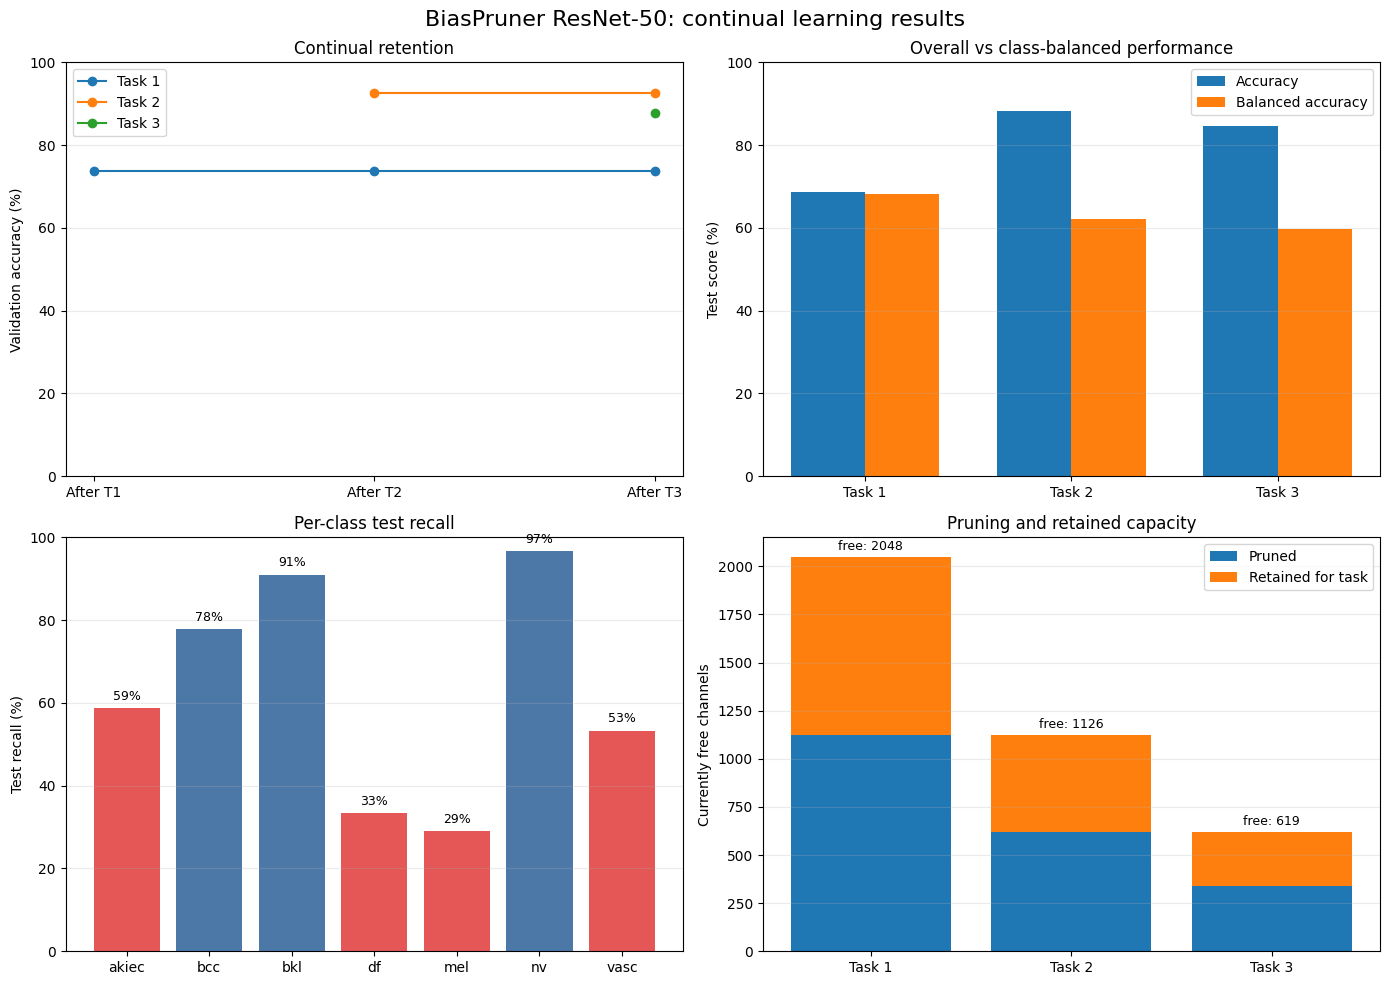

In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# A: continual validation retention
x = np.arange(3)
axes[0,0].plot(x, [73.77,73.77,73.77], marker='o', label='Task 1')
axes[0,0].plot([1,2], [92.58,92.58], marker='o', label='Task 2')
axes[0,0].plot([2], [87.88], marker='o', label='Task 3')
axes[0,0].set(xticks=x, xticklabels=['After T1','After T2','After T3'], ylabel='Validation accuracy (%)', title='Continual retention')
axes[0,0].set_ylim(0,100); axes[0,0].legend(); axes[0,0].grid(axis='y',alpha=.25)
# B: final test accuracy vs balanced accuracy
names=['Task 1','Task 2','Task 3']; acc=[68.57,88.28,84.65]; bacc=[68.30,62.16,59.70]
xx=np.arange(3); w=.36
axes[0,1].bar(xx-w/2,acc,w,label='Accuracy'); axes[0,1].bar(xx+w/2,bacc,w,label='Balanced accuracy')
axes[0,1].set(xticks=xx,xticklabels=names,ylabel='Test score (%)',title='Overall vs class-balanced performance'); axes[0,1].set_ylim(0,100); axes[0,1].legend(); axes[0,1].grid(axis='y',alpha=.25)
# C: class-level test recall
labels=['akiec','bcc','bkl','df','mel','nv','vasc']; recall=[58.82,77.78,90.98,33.33,29.10,96.66,53.33]
colors=['#4c78a8' if v>=60 else '#e45756' for v in recall]
axes[1,0].bar(labels,recall,color=colors); axes[1,0].set(ylabel='Test recall (%)',title='Per-class test recall'); axes[1,0].set_ylim(0,100); axes[1,0].grid(axis='y',alpha=.25)
for i,v in enumerate(recall): axes[1,0].text(i,v+2,f'{v:.0f}%',ha='center',fontsize=9)
# D: sequential free-channel allocation
free=np.array([2048,1126,619]); pruned=np.array([1126,619,340]); kept=np.array([922,507,279])
axes[1,1].bar(names,pruned,label='Pruned'); axes[1,1].bar(names,kept,bottom=pruned,label='Retained for task')
axes[1,1].set(ylabel='Currently free channels',title='Pruning and retained capacity'); axes[1,1].legend(); axes[1,1].grid(axis='y',alpha=.25)
for i,n in enumerate(free): axes[1,1].text(i,n+35,f'free: {n}',ha='center',fontsize=9)
fig.suptitle('BiasPruner ResNet-50: continual learning results',fontsize=16)
fig.tight_layout()
plt.show()

In [1]:
# Held-out sex fairness audit for the saved Task 3 model.
# Metrics are one-vs-rest per diagnosis within each task; positive class = diagnosis shown.
from pathlib import Path
import numpy as np, pandas as pd, torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit

SEED=42
TASKS=(('akiec','bcc'),('bkl','df'),('mel','nv','vasc'))
IMAGE_SIZE=224
OUT=Path('/kaggle/working/biaspruner_resnet50_reuse_55_full')
CKPT=OUT/'after_task_3.pt'
if not CKPT.exists(): raise FileNotFoundError(f'Saved Task 3 checkpoint not found: {CKPT}')

# Recreate the exact deterministic lesion-disjoint test partition used for training.
meta_paths=list(Path('/kaggle/input').rglob('HAM10000_metadata.csv'))
if not meta_paths: raise FileNotFoundError('HAM10000_metadata.csv is missing from /kaggle/input.')
meta=pd.read_csv(meta_paths[0]); image_map={}
for p in Path('/kaggle/input').rglob('*'):
    if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png'}: image_map.setdefault(p.stem,p)
meta['path']=meta.image_id.map(image_map)
meta=meta[meta.path.notna()].copy().reset_index(drop=True)
groups=meta['lesion_id'].fillna(meta.image_id) if 'lesion_id' in meta else meta.image_id
train_idx,hold_idx=next(GroupShuffleSplit(n_splits=1,test_size=.30,random_state=SEED).split(meta,meta.dx,groups))
hold=meta.iloc[hold_idx].reset_index(drop=True)
hgroups=hold['lesion_id'].fillna(hold.image_id) if 'lesion_id' in hold else hold.image_id
_,test_rel=next(GroupShuffleSplit(n_splits=1,test_size=1/3,random_state=SEED+1).split(hold,hold.dx,hgroups))
test_df=hold.iloc[test_rel].reset_index(drop=True)

# Load the saved backbone, task heads and channel masks without downloading weights.
device=torch.device('cpu')
checkpoint=torch.load(CKPT,map_location=device,weights_only=False)
net=models.resnet50(weights=None); net.fc=nn.Identity(); net.load_state_dict(checkpoint['model']); net.eval()
class TaskHead(nn.Module):
    def __init__(self,n): super().__init__(); self.fc=nn.Linear(2048,n)
    def forward(self,x): return self.fc(x)
heads=[]
for task,state in zip(TASKS,checkpoint['heads']):
    head=TaskHead(len(task)); head.load_state_dict(state); head.eval(); heads.append(head)
masks=[torch.as_tensor(m,dtype=torch.float32,device=device) for m in checkpoint['task_masks']]

class FairnessTestSet(Dataset):
    def __init__(self,frame,classes):
        self.frame=frame[frame.dx.isin(classes)].reset_index(drop=True); self.classes=tuple(classes)
        self.tf=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),transforms.ToTensor(),transforms.Normalize((.485,.456,.406),(.229,.224,.225))])
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i]
        with Image.open(row.path) as im: x=self.tf(im.convert('RGB'))
        return x,self.classes.index(row.dx),i

def backbone_features(x):
    x=net.maxpool(net.relu(net.bn1(net.conv1(x))))
    x=net.layer1(x); x=net.layer2(x); x=net.layer3(x); x=net.layer4(x)
    return F.adaptive_avg_pool2d(x,1).flatten(1)

rows=[]
for ti,classes in enumerate(TASKS):
    ds=FairnessTestSet(test_df,classes)
    loader=DataLoader(ds,batch_size=24,shuffle=False,num_workers=0)
    y_true=[]; y_pred=[]; sex=[]
    with torch.inference_mode():
        for x,y,row_idx in loader:
            z=backbone_features(x)
            pred=heads[ti](z*masks[ti]).argmax(1)
            y_true.extend(y.tolist()); y_pred.extend(pred.tolist())
            sex.extend(ds.frame.iloc[row_idx.tolist()]['sex'].fillna('unknown').astype(str).str.strip().str.lower().tolist())
    y_true=np.asarray(y_true); y_pred=np.asarray(y_pred); sex=np.asarray(sex)
    for ci,label in enumerate(classes):
        group_stats={}
        for group in ('female','male'):
            g=sex==group; positive=y_true==ci; predicted=y_pred==ci
            n=int(g.sum()); positives=int((g&positive).sum()); negatives=int((g&~positive).sum())
            selection=float((g&predicted).sum()/n) if n else np.nan
            tpr=float((g&positive&predicted).sum()/positives) if positives else np.nan
            fpr=float((g&~positive&predicted).sum()/negatives) if negatives else np.nan
            accuracy=float((g&(y_true==y_pred)).sum()/n) if n else np.nan
            group_stats[group]=(selection,tpr,fpr,accuracy,n,positives)
        f,m=group_stats['female'],group_stats['male']
        dp_diff=m[0]-f[0] if np.isfinite(m[0]) and np.isfinite(f[0]) else np.nan
        dp_ratio=min(m[0],f[0])/max(m[0],f[0]) if np.isfinite(m[0]) and np.isfinite(f[0]) and max(m[0],f[0])>0 else np.nan
        eo_gap=abs(m[1]-f[1]) if np.isfinite(m[1]) and np.isfinite(f[1]) else np.nan
        fpr_gap=abs(m[2]-f[2]) if np.isfinite(m[2]) and np.isfinite(f[2]) else np.nan
        eod_gap=max(eo_gap,fpr_gap) if np.isfinite(eo_gap) and np.isfinite(fpr_gap) else np.nan
        rows.append({'task':f'Task {ti+1}','diagnosis':label,'female_n':f[4],'male_n':m[4],
                     'female_support':f[5],'male_support':m[5],
                     'female_selection_rate':f[0],'male_selection_rate':m[0],
                     'DP_difference_male_minus_female':dp_diff,'DP_ratio_min_over_max':dp_ratio,
                     'female_TPR':f[1],'male_TPR':m[1],'equal_opportunity_gap':eo_gap,
                     'female_FPR':f[2],'male_FPR':m[2],'equalized_odds_gap':eod_gap,
                     'female_accuracy':f[3],'male_accuracy':m[3]})

fairness_df=pd.DataFrame(rows)
print(f'Checkpoint: {CKPT}')
print(f'Exact held-out test partition: {len(test_df)} images; sex values included: female/male; other or missing sex excluded per group comparison.')
print('DP = demographic parity (predicted diagnosis selection rate); DP difference is male minus female; ratio is min/max.')
print('Equal opportunity gap = absolute female/male TPR difference. Equalized odds gap = max(TPR gap, FPR gap).')
print('All rates are 0–1. Counts are shown because small subgroup/class support makes rates less stable.')
display(fairness_df.round(4))


FileNotFoundError: Saved Task 3 checkpoint not found: /kaggle/working/biaspruner_resnet50_reuse_55_full/after_task_3.pt

In [4]:
# Proposed Method: Historical Bias-Aware Channel Scoring
# Lightweight EMA memory and score adjustment; no model or data pipeline changes.
import torch

BETA = 0.8
ALPHA_TEMPORAL = 0.1

def historical_bias_update(raw_scores, memory, memory_valid, score_valid,
                           beta=BETA, alpha=ALPHA_TEMPORAL):
    """Return adjusted scores, next detached raw-score EMA, validity and positive deviation."""
    raw = raw_scores.detach()
    valid = score_valid.to(device=raw.device, dtype=torch.bool) & torch.isfinite(raw)
    if memory is None:
        previous = torch.zeros_like(raw)
        previous_valid = torch.zeros_like(valid)
    else:
        previous = memory.detach().to(device=raw.device, dtype=raw.dtype)
        previous_valid = memory_valid.detach().to(device=raw.device, dtype=torch.bool)
        if previous.shape != raw.shape or previous_valid.shape != valid.shape:
            raise ValueError("Historical score/mask dimensions must match current scores.")
    if previous.device != raw.device:
        raise ValueError("Historical memory and current scores must share a device.")

    deviation = torch.zeros_like(raw)
    comparable = valid & previous_valid
    deviation[comparable] = (raw[comparable] - previous[comparable]).clamp_min(0)
    proposed = raw.clone()
    proposed[valid] = raw[valid] + alpha * deviation[valid]

    next_memory = previous.clone()
    first = valid & ~previous_valid
    next_memory[first] = raw[first]
    continuing = valid & previous_valid
    next_memory[continuing] = beta * previous[continuing] + (1.0-beta) * raw[continuing]
    next_valid = previous_valid | valid
    return (proposed.detach(), next_memory.detach(), next_valid.detach(),
            deviation.detach())

# Required smoke test: first-task score is unchanged, EMA uses raw finite scores,
# and selection count is fixed by the existing free-channel mask and pruning ratio.
_smoke_raw = torch.tensor([0.25, 0.80, -0.10, 0.40], dtype=torch.float32)
_smoke_valid = torch.tensor([True, True, True, False])
_smoke_free = torch.tensor([True, True, False, True])
_smoke_first, _smoke_mem, _smoke_hist_valid, _smoke_dev = historical_bias_update(
    _smoke_raw, None, torch.zeros_like(_smoke_valid), _smoke_valid)
assert torch.equal(_smoke_first[_smoke_valid], _smoke_raw[_smoke_valid])
assert torch.isfinite(_smoke_mem).all()
_smoke_second_raw = _smoke_raw + torch.tensor([0.10, -0.20, 0.50, 0.0])
_smoke_second, _smoke_mem2, _smoke_valid2, _smoke_dev2 = historical_bias_update(
    _smoke_second_raw, _smoke_mem, _smoke_hist_valid, _smoke_valid)
assert torch.allclose(_smoke_dev2[:3], torch.tensor([0.10, 0.0, 0.50]))
assert torch.allclose(_smoke_second[:3],
                      _smoke_second_raw[:3] + ALPHA_TEMPORAL*_smoke_dev2[:3])
_smoke_nprune = round(0.55 * int(_smoke_free.sum()))
_smoke_candidates = torch.where(_smoke_free & _smoke_valid)[0]
_smoke_selected = _smoke_candidates[torch.topk(
    _smoke_second[_smoke_candidates], _smoke_nprune).indices]
assert len(_smoke_selected) == _smoke_nprune
assert not _smoke_selected.eq(2).any() and not _smoke_selected.eq(3).any()  # occupied/non-free channel stays protected
print("Historical scoring smoke test passed: first-task raw score, finite EMA, "
      "positive deviation, fixed pruning count, and protected non-free channels.")

BASELINE_TEST = {
    "Task 1": {"accuracy":0.6857,"balanced_accuracy":0.6830,"macro_f1":0.6816,
               "per_class_recall":{"akiec":0.5882,"bcc":0.7778}},
    "Task 2": {"accuracy":0.8828,"balanced_accuracy":0.6216,"macro_f1":0.5736,
               "per_class_recall":{"bkl":0.9098,"df":0.3333}},
    "Task 3": {"accuracy":0.8465,"balanced_accuracy":0.5970,"macro_f1":0.6062,
               "per_class_recall":{"mel":0.2910,"nv":0.9666,"vasc":0.5333}},
}
print("Baseline test metrics captured from the existing notebook report; "
      "proposed metrics will be populated only after the historical-bias run.")

# Full historical-bias-aware experiment cell follows.
# Fresh full-data BiasPruner-style continual run on HAM10000 with ResNet-50.
# Unit = one of the 2048 output channels from ResNet-50 layer4[-1].
# Per task: 20 GCE epochs -> prune top 55% of currently free channels -> 20 WCE epochs.
# Retained subnetworks (the remaining 45% of free channels) are reused and frozen later.
import gc, json, random
from pathlib import Path
import numpy as np, pandas as pd, torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score

# Clear prior attempt models so the full run has GPU memory available.
for _name in ('net','net0','model','mini','head','heads','optimizer','opt','task_masks','task1_mask'):
    globals().pop(_name,None)
for _name, _obj in list(globals().items()):
    if isinstance(_obj, (nn.Module, torch.optim.Optimizer)): globals().pop(_name,None)
del _name, _obj
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

SEED=42; TASKS=(('akiec','bcc'),('bkl','df'),('mel','nv','vasc'))
TAU=0.65; PRUNE_RATIO=0.55; GCE_EPOCHS=20; WCE_EPOCHS=20; GCE_Q=0.7; ALPHA=0.6
IMAGE_SIZE=224; BATCH_SIZE=32; NUM_WORKERS=2; LR=1e-4; MIN_SUPPORT=2
OUT=Path('/kaggle/working/biaspruner_resnet50_reuse_55_historical_bias'); OUT.mkdir(parents=True,exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device={device}; ResNet-50 ImageNet V2; tau={TAU}; prune={PRUNE_RATIO:.0%} of free channels; GCE/WCE={GCE_EPOCHS}/{WCE_EPOCHS} epochs',flush=True)
print('Adaptive implementation: channel units are the final 2048 ResNet layer4 outputs; earlier backbone weights and all BN running statistics stay fixed.',flush=True)

# Full HAM10000 with lesion-disjoint 70/20/10 partitions.
meta_paths=list(Path('/kaggle/input').rglob('HAM10000_metadata.csv'))
if not meta_paths: raise FileNotFoundError('HAM10000_metadata.csv is missing from /kaggle/input.')
meta=pd.read_csv(meta_paths[0]); image_map={}
for p in Path('/kaggle/input').rglob('*'):
    if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png'}: image_map.setdefault(p.stem,p)
meta['path']=meta.image_id.map(image_map); meta=meta[meta.path.notna()].copy().reset_index(drop=True)
if not set(sum((list(t) for t in TASKS),[])).issubset(set(meta.dx)): raise RuntimeError('HAM10000 is missing one or more requested task classes.')
groups=meta['lesion_id'].fillna(meta.image_id) if 'lesion_id' in meta else meta.image_id
train_idx,hold_idx=next(GroupShuffleSplit(n_splits=1,test_size=.30,random_state=SEED).split(meta,meta.dx,groups))
train_df=meta.iloc[train_idx].reset_index(drop=True); hold=meta.iloc[hold_idx].reset_index(drop=True)
hgroups=hold['lesion_id'].fillna(hold.image_id) if 'lesion_id' in hold else hold.image_id
val_rel,test_rel=next(GroupShuffleSplit(n_splits=1,test_size=1/3,random_state=SEED+1).split(hold,hold.dx,hgroups))
val_df=hold.iloc[val_rel].reset_index(drop=True); test_df=hold.iloc[test_rel].reset_index(drop=True)
def lesion_set(df): return set((df['lesion_id'].fillna(df.image_id) if 'lesion_id' in df else df.image_id).astype(str))
assert not (lesion_set(train_df)&lesion_set(val_df) or lesion_set(train_df)&lesion_set(test_df) or lesion_set(val_df)&lesion_set(test_df)), 'Lesion leakage across splits.'
print(f'Matched images={len(meta)}; split train/val/test={len(train_df)}/{len(val_df)}/{len(test_df)}',flush=True)

class HamTask(Dataset):
    def __init__(self,frame,classes,augment=False):
        self.frame=frame[frame.dx.isin(classes)].reset_index(drop=True); self.classes=tuple(classes)
        ops=[transforms.Resize((IMAGE_SIZE,IMAGE_SIZE))]
        if augment: ops += [transforms.RandomHorizontalFlip(),transforms.RandomRotation(10)]
        ops += [transforms.ToTensor(),transforms.Normalize((.485,.456,.406),(.229,.224,.225))]
        self.tf=transforms.Compose(ops)
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i]
        with Image.open(row.path) as im: x=self.tf(im.convert('RGB'))
        return x,self.classes.index(row.dx),i

def make_loader(frame,classes,training):
    ds=HamTask(frame,classes,augment=training)
    if not len(ds): raise RuntimeError(f'No rows for task classes {classes}.')
    labels=np.array([ds.classes.index(x) for x in ds.frame.dx]); counts=np.bincount(labels,minlength=len(classes))
    if np.any(counts==0): raise RuntimeError(f'Task {classes} missing a class in this split: {counts.tolist()}')
    if training:
        weights=torch.as_tensor(1.0/counts[labels],dtype=torch.double)
        sampler=WeightedRandomSampler(weights,num_samples=len(ds),replacement=True)
        loader=DataLoader(ds,batch_size=BATCH_SIZE,sampler=sampler,num_workers=NUM_WORKERS,pin_memory=True,persistent_workers=False)
    else: loader=DataLoader(ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=True,persistent_workers=False)
    return loader
trainL=[]; scoreL=[]; valL=[]; testL=[]
for task in TASKS:
    trainL.append(make_loader(train_df,task,True)); scoreL.append(make_loader(train_df,task,False))
    valL.append(make_loader(val_df,task,False)); testL.append(make_loader(test_df,task,False))
    print(f'{task}: train={len(trainL[-1].dataset)} val={len(valL[-1].dataset)} test={len(testL[-1].dataset)}',flush=True)

try: weights=models.ResNet50_Weights.IMAGENET1K_V2
except AttributeError: weights='IMAGENET1K_V2'
net=models.resnet50(weights=weights); net.fc=nn.Identity(); net=net.to(device)
for p in net.parameters(): p.requires_grad_(False)
last=net.layer4[-1]; conv=last.conv3; bn=last.bn3; WIDTH=conv.out_channels
conv.weight.requires_grad_(True)
if conv.bias is not None: conv.bias.requires_grad_(True)
bn.weight.requires_grad_(True); bn.bias.requires_grad_(True)
print(f'Loaded ResNet-50; channel capacity={WIDTH}; initial free={WIDTH}',flush=True)

class TaskHead(nn.Module):
    def __init__(self,n): super().__init__(); self.fc=nn.Linear(WIDTH,n)
    def forward(self,x): return self.fc(x)
def backbone_features(x):
    x=net.maxpool(net.relu(net.bn1(net.conv1(x))))
    x=net.layer1(x); x=net.layer2(x); x=net.layer3(x); fmap=net.layer4(x)
    return F.adaptive_avg_pool2d(fmap,1).flatten(1),fmap
def metrics(head,loader,classes,mask):
    net.eval(); head.eval(); ys=[]; ps=[]
    with torch.no_grad():
        for x,y,_ in loader:
            z,_=backbone_features(x.to(device,non_blocking=True)); ps.extend(head(z*mask).argmax(1).cpu().tolist()); ys.extend(y.tolist())
    rec=recall_score(ys,ps,labels=list(range(len(classes))),average=None,zero_division=0)
    return {'accuracy':float(accuracy_score(ys,ps)),'balanced_accuracy':float(balanced_accuracy_score(ys,ps)),
            'macro_f1':float(f1_score(ys,ps,average='macro',zero_division=0)),
            'per_class_recall':{c:float(r) for c,r in zip(classes,rec)},'n':len(ys)}
def new_optimizer(head):
    params=[conv.weight,bn.weight,bn.bias]+([conv.bias] if conv.bias is not None else [])
    return torch.optim.AdamW([{'params':params},{'params':head.parameters()}],lr=LR,weight_decay=0)
def train_epoch(head,loader,active_mask,train_rows,opt,gce=False,sample_weights=None):
    net.train(); head.train()
    for m in net.modules():
        if isinstance(m,nn.BatchNorm2d): m.eval()
    rowmask=train_rows.to(device=device,dtype=conv.weight.dtype)
    hooks=[conv.weight.register_hook(lambda g,m=rowmask:g*m[:,None,None,None]),
           bn.weight.register_hook(lambda g,m=rowmask:g*m),bn.bias.register_hook(lambda g,m=rowmask:g*m)]
    if conv.bias is not None: hooks.append(conv.bias.register_hook(lambda g,m=rowmask:g*m))
    losses=[]; correct=seen=0
    try:
        for x,y,row in loader:
            x=x.to(device,non_blocking=True); y=y.to(device); opt.zero_grad(set_to_none=True)
            z,_=backbone_features(x); logits=head(z*active_mask)
            if gce:
                pt=logits.softmax(1).gather(1,y[:,None]).squeeze(1); lv=(1-pt.clamp_min(1e-7).pow(GCE_Q))/GCE_Q
            else: lv=F.cross_entropy(logits,y,reduction='none')
            if sample_weights is not None: lv=lv*sample_weights[row.long()].to(device).clamp(.05,10)
            loss=lv.mean()
            if not torch.isfinite(loss): raise FloatingPointError('Non-finite training loss; stopping this experiment.')
            loss.backward(); opt.step(); losses.append(float(loss.detach())); correct+=int((logits.argmax(1)==y).sum()); seen+=len(y)
    finally:
        for h in hooks: h.remove()
    return float(np.mean(losses)),correct/max(seen,1)
@torch.no_grad()
def score_channels(head,loader,active_mask,free_mask):
    net.eval(); head.eval(); nclass=head.fc.out_features
    es=torch.zeros(nclass,WIDTH,dtype=torch.float64); hs=es.clone(); en=torch.zeros(nclass,dtype=torch.long); hn=en.clone(); sample_gce=torch.zeros(len(loader.dataset))
    for x,y,row in loader:
        x=x.to(device,non_blocking=True); y=y.to(device); z,fmap=backbone_features(x); logits=head(z*active_mask)
        prob=logits.softmax(1); conf,pred=prob.max(1); easy=pred.eq(y)&conf.ge(TAU); hard=pred.ne(y)&conf.ge(TAU)
        pt=prob.gather(1,y[:,None]).squeeze(1); sample_gce[row.long()]=((1-pt.clamp_min(1e-7).pow(GCE_Q))/GCE_Q).cpu()
        var=(fmap.float()*active_mask.view(1,-1,1,1)).var((2,3),unbiased=False).cpu()
        for c in range(nclass):
            e=y.eq(c).cpu()&easy.cpu(); h=y.eq(c).cpu()&hard.cpu(); en[c]+=e.sum(); hn[c]+=h.sum()
            if e.any(): es[c]+=var[e].sum(0).double()
            if h.any(): hs[c]+=var[h].sum(0).double()
    eligible=(en>=MIN_SUPPORT)&(hn>=MIN_SUPPORT)
    if not eligible.any(): raise RuntimeError(f'Bias scoring has no eligible easy/hard class at tau={TAU}: easy={en.tolist()}, hard={hn.tolist()}. Stop to revise scoring/training.')
    scores=torch.stack([es[c]/en[c]-hs[c]/hn[c] for c in torch.where(eligible)[0]]).mean(0).float()
    score_valid=torch.isfinite(scores)
    print(f'  scoring support: easy={en.tolist()}, hard={hn.tolist()}, eligible={int(eligible.sum())}/{nclass}',flush=True)
    return scores,sample_gce,score_valid

occupied=torch.zeros(WIDTH,dtype=torch.bool,device=device)
heads=[]; task_masks=[]; results=[]
historical_memory=None
historical_valid=torch.zeros(WIDTH,dtype=torch.bool)
score_diagnostics=[]
for ti,classes in enumerate(TASKS):
    print(f'\n===== TASK {ti+1}/3 {classes} =====',flush=True)
    free=~occupied; nfree=int(free.sum())
    if nfree<2: raise RuntimeError(f'Only {nfree} free channels remain before Task {ti+1}.')
    # Snapshot old subnet rows and heads; later training must leave them bitwise unchanged.
    old_rows=occupied.clone(); old_w=conv.weight[old_rows].detach().clone(); old_bw=bn.weight[old_rows].detach().clone(); old_bb=bn.bias[old_rows].detach().clone()
    old_heads=[[p.detach().clone() for p in h.parameters()] for h in heads]
    head=TaskHead(len(classes)).to(device); heads.append(head)
    all_active=torch.ones(WIDTH,device=device); opt=new_optimizer(head)
    for ep in range(GCE_EPOCHS):
        loss,tracc=train_epoch(head,trainL[ti],all_active,free,opt,gce=True)
        vm=metrics(head,valL[ti],classes,all_active)
        if not np.isfinite(vm['accuracy']): raise FloatingPointError('Non-finite validation metric; stopping.')
        print(f'  GCE {ep+1:02d}/{GCE_EPOCHS} loss={loss:.4f} train_acc={tracc:.4f} val_acc={vm["accuracy"]:.4f} val_bal_acc={vm["balanced_accuracy"]:.4f}',flush=True)
    before=metrics(head,valL[ti],classes,all_active); print('  validation before prune:',before,flush=True)
    raw_scores,gce_weights,score_valid=score_channels(head,scoreL[ti],all_active,free)
    prior_memory=None if historical_memory is None else historical_memory.detach().clone()
    proposed_scores,historical_memory,historical_valid,deviation=historical_bias_update(
        raw_scores,historical_memory,historical_valid,score_valid,BETA,ALPHA_TEMPORAL)
    # Apply free-channel eligibility only at selection; occupied channels remain protected.
    nprune=min(round(PRUNE_RATIO*nfree),nfree-1)
    eligible_candidates=free.cpu() & score_valid
    candidates=torch.where(eligible_candidates)[0]
    if len(candidates)<nprune: raise RuntimeError(f"Only {len(candidates)} free channels have valid scores; need {nprune} to preserve the pruning count.")
    pruned=candidates[torch.topk(proposed_scores[candidates],nprune).indices].to(device) if nprune else candidates[:0].to(device)
    assert len(pruned)==nprune and not occupied[pruned].any(), 'Pruning count changed or an occupied channel was selected.'
    score_diagnostics.append({
        'task':ti+1,'raw_scores':raw_scores.detach().cpu().clone(),
        'historical_memory':None if prior_memory is None else prior_memory.cpu(),
        'historical_memory_after':historical_memory.detach().cpu().clone(),
        'deviation':deviation.detach().cpu().clone(),
        'proposed_scores':proposed_scores.detach().cpu().clone(),
        'score_valid':score_valid.detach().cpu().clone(),
        'free_mask':free.detach().cpu().clone(),
        'selected_indices':pruned.detach().cpu().clone(),
        'n_selected':int(nprune),
    })
    keep=free.clone(); keep[pruned]=False; newly_retained=int(keep.sum())
    taskmask=(occupied|keep).float(); immediate=metrics(head,valL[ti],classes,taskmask)
    print(f'  pruned {len(pruned)}/{nfree} currently-free channels; retained new={newly_retained}; immediate masked val_acc={immediate["accuracy"]:.4f}',flush=True)
    wce_opt=new_optimizer(head); last_wce=None
    for ep in range(WCE_EPOCHS):
        loss,tracc=train_epoch(head,trainL[ti],taskmask,keep,wce_opt,gce=False,sample_weights=torch.exp(ALPHA*gce_weights))
        vm=metrics(head,valL[ti],classes,taskmask); last_wce=vm
        if not np.isfinite(vm['accuracy']): raise FloatingPointError('Non-finite WCE validation metric; stopping.')
        print(f'  WCE {ep+1:02d}/{WCE_EPOCHS} loss={loss:.4f} train_acc={tracc:.4f} val_acc={vm["accuracy"]:.4f} val_bal_acc={vm["balanced_accuracy"]:.4f}',flush=True)
    task_masks.append(taskmask.detach().clone()); occupied|=keep
    for p in head.parameters(): p.requires_grad_(False)
    if old_rows.any():
        assert torch.equal(old_w,conv.weight[old_rows]) and torch.equal(old_bw,bn.weight[old_rows]) and torch.equal(old_bb,bn.bias[old_rows]), 'Previously retained channel rows changed.'
        for old,params in enumerate(old_heads): assert all(torch.equal(p,q) for p,q in zip(params,heads[old].parameters())), f'Previous Task {old+1} head changed.'
        print('  freeze check: prior retained rows and prior task heads unchanged bitwise.',flush=True)
    row_summary={f'task_{j+1}':metrics(heads[j],valL[j],TASKS[j],task_masks[j]) for j in range(ti+1)}
    print(f'  validation across learned tasks after Task {ti+1}:',row_summary,flush=True)
    task_result={'task':ti+1,'classes':classes,'free_before':nfree,'pruned':int(len(pruned)),'retained_new':newly_retained,
                 'validation_before_prune':before,'validation_immediately_after_mask':immediate,'validation_after_wce':last_wce,'validation_all_tasks':row_summary}
    results.append(task_result)
    torch.save({'model':net.state_dict(),'heads':[h.state_dict() for h in heads],'task_masks':[m.detach().cpu() for m in task_masks],
                'classes':TASKS[:ti+1],'occupied':occupied.detach().cpu(),'config':{'tau':TAU,'prune_ratio':PRUNE_RATIO,'gce_epochs':GCE_EPOCHS,'wce_epochs':WCE_EPOCHS,'image_size':IMAGE_SIZE},'results':results},OUT/f'after_task_{ti+1}.pt')
    (OUT/'results.json').write_text(json.dumps(results,indent=2)); print(f'  checkpoint saved: {OUT}/after_task_{ti+1}.pt',flush=True)

final_val={}; final_test={}
for i,classes in enumerate(TASKS):
    final_val[f'task_{i+1}']=metrics(heads[i],valL[i],classes,task_masks[i])
    final_test[f'task_{i+1}']=metrics(heads[i],testL[i],classes,task_masks[i])
print('FINAL validation after Task 3:',json.dumps(final_val,indent=2),flush=True)
print('FINAL held-out test after Task 3:',json.dumps(final_test,indent=2),flush=True)
results.append({'final_validation_after_task_3':final_val,'final_test_after_task_3':final_test})
(OUT/'results.json').write_text(json.dumps(results,indent=2))
diagnostic_rows=[]
for entry in score_diagnostics:
    width=len(entry['raw_scores'])
    old=entry['historical_memory']
    chosen=set(entry['selected_indices'].tolist())
    for channel in range(width):
        diagnostic_rows.append({
            'task':entry['task'],'channel':channel,'free':bool(entry['free_mask'][channel]),
            'valid_raw_score':bool(entry['score_valid'][channel]),
            'original_score':float(entry['raw_scores'][channel]),
            'historical_memory_before_task':float(old[channel]) if old is not None else np.nan,
            'historical_memory_after_task':float(entry['historical_memory_after'][channel]),
            'emerging_deviation':float(entry['deviation'][channel]),
            'proposed_score':float(entry['proposed_scores'][channel]),
            'selected_for_pruning':channel in chosen,
            'selected_count':entry['n_selected'],
        })
pd.DataFrame(diagnostic_rows).to_csv(OUT/'historical_score_diagnostics.csv',index=False)
print('Historical-score diagnostics saved:',OUT/'historical_score_diagnostics.csv',flush=True)
print('COMPLETE; artifacts:',OUT,flush=True)

Historical scoring smoke test passed: first-task raw score, finite EMA, positive deviation, fixed pruning count, and protected non-free channels.
Baseline test metrics captured from the existing notebook report; proposed metrics will be populated only after the historical-bias run.
Device=cuda; ResNet-50 ImageNet V2; tau=0.65; prune=55% of free channels; GCE/WCE=20/20 epochs
Adaptive implementation: channel units are the final 2048 ResNet layer4 outputs; earlier backbone weights and all BN running statistics stay fixed.
Matched images=10015; split train/val/test=7002/2007/1006
('akiec', 'bcc'): train=588 val=183 test=70
('bkl', 'df'): train=830 val=256 test=128
('mel', 'nv', 'vasc'): train=5584 val=1568 test=808
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 171MB/s] 


Loaded ResNet-50; channel capacity=2048; initial free=2048

===== TASK 1/3 ('akiec', 'bcc') =====
  GCE 01/20 loss=0.5334 train_acc=0.5612 val_acc=0.5355 val_bal_acc=0.5546
  GCE 02/20 loss=0.5037 train_acc=0.6701 val_acc=0.5847 val_bal_acc=0.5792
  GCE 03/20 loss=0.4369 train_acc=0.7415 val_acc=0.6448 val_bal_acc=0.6485
  GCE 04/20 loss=0.4338 train_acc=0.6888 val_acc=0.6393 val_bal_acc=0.6407
  GCE 05/20 loss=0.4044 train_acc=0.7041 val_acc=0.6667 val_bal_acc=0.6599
  GCE 06/20 loss=0.3705 train_acc=0.7500 val_acc=0.6940 val_bal_acc=0.6883
  GCE 07/20 loss=0.3573 train_acc=0.7500 val_acc=0.6667 val_bal_acc=0.6671
  GCE 08/20 loss=0.3268 train_acc=0.7874 val_acc=0.6721 val_bal_acc=0.6802
  GCE 09/20 loss=0.3198 train_acc=0.7789 val_acc=0.6776 val_bal_acc=0.6781
  GCE 10/20 loss=0.3050 train_acc=0.7993 val_acc=0.6940 val_bal_acc=0.6843
  GCE 11/20 loss=0.2972 train_acc=0.8027 val_acc=0.6776 val_bal_acc=0.6801
  GCE 12/20 loss=0.2899 train_acc=0.8231 val_acc=0.7158 val_bal_acc=0.7188
  

Baseline versus historical bias-aware held-out test performance


,Task,Metric,Baseline (%),Historical bias-aware (%)
0,Task 1,Accuracy,68.57,NaN
1,Task 1,Balanced Accuracy,68.30,NaN
2,Task 1,Macro F1,68.16,NaN
3,Task 1,Recall: akiec,58.82,NaN
4,Task 1,Recall: bcc,77.78,NaN
5,Task 2,Accuracy,88.28,NaN
6,Task 2,Balanced Accuracy,62.16,NaN
7,Task 2,Macro F1,57.36,NaN
8,Task 2,Recall: bkl,90.98,NaN
9,Task 2,Recall: df,33.33,NaN



Continual-learning validation retention


,After learning,Evaluated task,Validation accuracy (%),Balanced accuracy (%),Macro F1 (%),Samples
0,Task 1,Task 1,73.77,73.48,73.54,183
1,Task 2,Task 1,73.77,73.48,73.54,183
2,Task 2,Task 2,92.58,77.67,75.88,256
3,Task 3,Task 1,73.77,73.48,73.54,183
4,Task 3,Task 2,92.58,77.67,75.88,256
5,Task 3,Task 3,87.95,74.44,71.37,1568



Per-class held-out test recall


,Task,Diagnosis,Test recall (%)
0,Task 1,akiec,58.82
1,Task 1,bcc,77.78
2,Task 2,bkl,90.98
3,Task 2,df,33.33
4,Task 3,mel,29.10
5,Task 3,nv,96.66
6,Task 3,vasc,53.33


... (3 outputs left out)

,Task,Diagnosis,Female n,Male n,Female positives,Male positives,Female selection rate,Male selection rate,DP difference (male - female),DP ratio (min/max),Female TPR,Male TPR,Equal opportunity gap,Female FPR,Male FPR,Equalized odds gap,Female accuracy,Male accuracy
0,Task 1,akiec,30,40,9,25,0.3333,0.4500,0.1167,0.7407,0.6667,0.5600,0.1067,0.1905,0.2667,0.1067,0.7667,0.6250
1,Task 1,bcc,30,40,21,15,0.6667,0.5500,-0.1167,0.8250,0.8095,0.7333,0.0762,0.3333,0.4400,0.1067,0.7667,0.6250
2,Task 2,bkl,66,62,63,59,0.9697,0.8226,-0.1471,0.8483,0.9683,0.8475,0.1208,1.0000,0.3333,0.6667,0.9242,0.8387
3,Task 2,df,66,62,3,3,0.0303,0.1774,0.1471,0.1708,0.0000,0.6667,0.6667,0.0317,0.1525,0.6667,0.9242,0.8387
4,Task 3,mel,388,415,53,81,0.0464,0.1012,0.0548,0.4584,0.2453,0.3210,0.0757,0.0149,0.0479,0.0757,0.8711,0.8217
5,Task 3,nv,388,415,331,323,0.9278,0.8819,-0.0459,0.9505,0.9698,0.9628,0.0069,0.6842,0.5978,0.0864,0.8711,0.8217
6,Task 3,vasc,388,415,4,11,0.0258,0.0169,-0.0089,0.6545,1.0000,0.3636,0.6364,0.0156,0.0074,0.6364,0.8711,0.8217



Historical score diagnostics


,task,channel,free,valid_raw_score,original_score,historical_memory_before_task,historical_memory_after_task,emerging_deviation,proposed_score,selected_for_pruning,selected_count
0,1,0,True,True,0.214969,NaN,0.214969,0.000000,0.214969,True,1126
1,1,1,True,True,-0.531794,NaN,-0.531794,0.000000,-0.531794,False,1126
2,1,2,True,True,0.000198,NaN,0.000198,0.000000,0.000198,False,1126
3,1,3,True,True,0.109698,NaN,0.109698,0.000000,0.109698,True,1126
4,1,4,True,True,-0.336092,NaN,-0.336092,0.000000,-0.336092,False,1126
...,...,...,...,...,...,...,...,...,...,...,...
6139,3,2043,False,True,0.001199,-0.057089,-0.045431,0.058288,0.007028,False,340
6140,3,2044,False,True,-0.059480,-0.044686,-0.047645,0.000000,-0.059480,False,340
6141,3,2045,False,True,0.005288,-0.002777,-0.001164,0.008065,0.006094,False,340
6142,3,2046,True,True,-0.043108,0.339999,0.263378,0.000000,-0.043108,True,340


Selected channel indices by task: {1: [0, 3, 5, 6, 9, 10, 11, 12, 13, 14, 16, 17, 18, 19, 21, 26, 27, 29, 30, 31, 33, 34, 36, 37, 38, 39, 40, 41, 43, 44, 45, 46, 48, 50, 51, 54, 55, 56, 57, 58, 61, 62, 65, 67, 68, 69, 70, 73, 75, 78, 80, 81, 82, 84, 87, 88, 90, 92, 93, 95, 98, 99, 108, 109, 110, 111, 112, 114, 116, 117, 119, 120, 122, 123, 128, 133, 139, 140, 141, 142, 146, 148, 150, 151, 152, 154, 156, 158, 160, 164, 165, 166, 169, 170, 173, 174, 175, 176, 180, 182, 184, 186, 188, 189, 190, 192, 193, 198, 201, 203, 205, 207, 211, 215, 216, 218, 219, 220, 222, 223, 224, 226, 228, 229, 230, 231, 232, 234, 235, 237, 238, 240, 241, 243, 245, 246, 248, 250, 252, 254, 255, 257, 258, 259, 262, 263, 264, 267, 268, 276, 277, 278, 279, 280, 281, 284, 285, 286, 292, 295, 297, 298, 300, 303, 305, 313, 314, 316, 317, 318, 319, 321, 322, 326, 327, 331, 332, 338, 341, 343, 344, 345, 346, 348, 349, 351, 352, 353, 355, 356, 357, 359, 360, 363, 364, 365, 367, 368, 369, 371, 372, 373, 374, 375, 376, 379

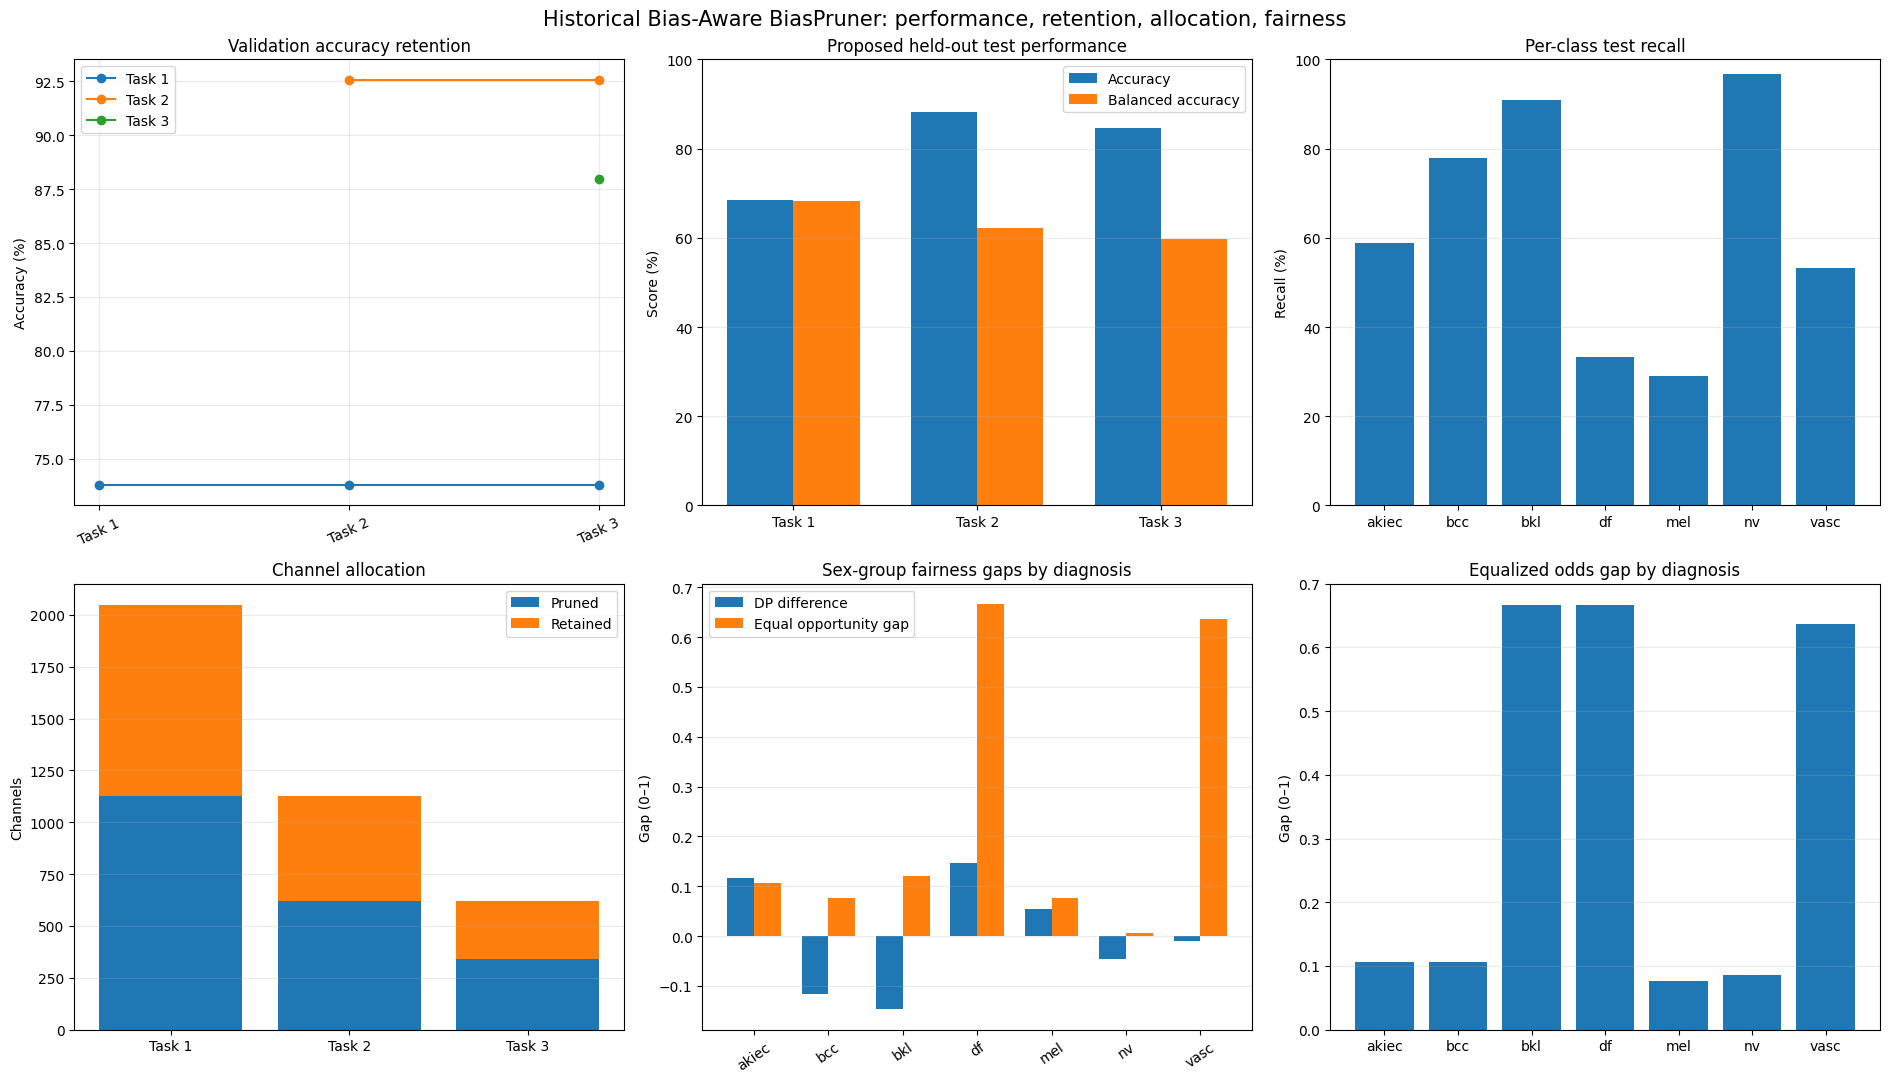


Full report tables saved under: /kaggle/working/biaspruner_resnet50_reuse_55_historical_bias


In [5]:
# Full report: task performance, continual retention, channel allocation,
# fairness metrics, and plots for the historical bias-aware run.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix

# Keep baseline values from the notebook's existing held-out test report.
if "BASELINE_TEST" not in globals():
    BASELINE_TEST = {
        "task_1": {
            "accuracy": 0.6857, "balanced_accuracy": 0.6830, "macro_f1": 0.6816,
            "per_class_recall": {"akiec": 0.5882, "bcc": 0.7778},
        },
        "task_2": {
            "accuracy": 0.8828, "balanced_accuracy": 0.6216, "macro_f1": 0.5736,
            "per_class_recall": {"bkl": 0.9098, "df": 0.3333},
        },
        "task_3": {
            "accuracy": 0.8465, "balanced_accuracy": 0.5970, "macro_f1": 0.6062,
            "per_class_recall": {"mel": 0.2910, "nv": 0.9666, "vasc": 0.5333},
        },
    }

if "final_test" not in globals() or "final_val" not in globals():
    raise RuntimeError(
        "Run the full historical-bias experiment cell first; "
        "final_test and final_val are not available."
    )

# 1. Baseline versus proposed held-out test metrics.
comparison_rows = []
for task_name, baseline in BASELINE_TEST.items():
    proposed = final_test.get(task_name, {})
    for metric in ("accuracy", "balanced_accuracy", "macro_f1"):
        comparison_rows.append({
            "Task": task_name.replace("_", " ").title(),
            "Metric": metric.replace("_", " ").title(),
            "Baseline (%)": 100 * baseline[metric],
            "Historical bias-aware (%)":
                100 * proposed[metric] if metric in proposed else np.nan,
        })
    for class_name, base_recall in baseline["per_class_recall"].items():
        proposed_recall = proposed.get("per_class_recall", {}).get(class_name)
        comparison_rows.append({
            "Task": task_name.replace("_", " ").title(),
            "Metric": f"Recall: {class_name}",
            "Baseline (%)": 100 * base_recall,
            "Historical bias-aware (%)":
                100 * proposed_recall if proposed_recall is not None else np.nan,
        })

comparison_df = pd.DataFrame(comparison_rows)
print("Baseline versus historical bias-aware held-out test performance")
display(comparison_df.round(2))

# 2. Validation accuracy for every previously learned task after each task stage.
task_runs = [
    item for item in results
    if isinstance(item, dict) and isinstance(item.get("task"), int)
]
retention_rows = []
for stage in task_runs:
    for task_key, metric in stage.get("validation_all_tasks", {}).items():
        retention_rows.append({
            "After learning": f"Task {stage['task']}",
            "Evaluated task": task_key.replace("_", " ").title(),
            "Validation accuracy (%)": 100 * metric["accuracy"],
            "Balanced accuracy (%)": 100 * metric["balanced_accuracy"],
            "Macro F1 (%)": 100 * metric["macro_f1"],
            "Samples": metric.get("n", np.nan),
        })

retention_df = pd.DataFrame(retention_rows)
print("\nContinual-learning validation retention")
display(retention_df.round(2))

# 3. Per-class proposed test recall.
recall_rows = []
for task_key, metric in final_test.items():
    for diagnosis, recall in metric["per_class_recall"].items():
        recall_rows.append({
            "Task": task_key.replace("_", " ").title(),
            "Diagnosis": diagnosis,
            "Test recall (%)": 100 * recall,
        })

recall_df = pd.DataFrame(recall_rows)
print("\nPer-class held-out test recall")
display(recall_df.round(2))

# 4. Channel allocation and pruning counts.
allocation_rows = []
for stage in task_runs:
    free = int(stage["free_before"])
    pruned = int(stage["pruned"])
    retained = int(stage["retained_new"])
    allocation_rows.append({
        "Task": f"Task {stage['task']}",
        "Free before task": free,
        "Pruned": pruned,
        "Retained for task": retained,
        "Pruned (%)": 100 * pruned / free if free else np.nan,
    })

allocation_df = pd.DataFrame(allocation_rows)
print("\nChannel allocation")
display(allocation_df.round(2))

# 5. Sex fairness on the same held-out test samples and task-specific heads.
#    Each diagnosis is treated as positive versus the other diagnoses in that task.
if not all(name in globals() for name in ("heads", "task_masks", "testL", "backbone_features", "device")):
    raise RuntimeError("Model, masks, or test loaders are unavailable for fairness evaluation.")

fairness_rows = []
test_predictions = {}
has_sex = all("sex" in loader.dataset.frame.columns for loader in testL)

if has_sex:
    net.eval()
    for task_index, classes in enumerate(TASKS):
        loader = testL[task_index]
        dataset = loader.dataset
        y_true, y_pred, groups = [], [], []

        with torch.inference_mode():
            for images, labels, row_indices in loader:
                images = images.to(device, non_blocking=True)
                features, _ = backbone_features(images)
                predictions = heads[task_index](
                    features * task_masks[task_index]
                ).argmax(1)

                y_true.extend(labels.cpu().tolist())
                y_pred.extend(predictions.cpu().tolist())
                groups.extend(
                    dataset.frame.iloc[row_indices.tolist()]["sex"]
                    .fillna("unknown").astype(str).str.strip().str.lower().tolist()
                )

        y_true = np.asarray(y_true)
        y_pred = np.asarray(y_pred)
        groups = np.asarray(groups)
        test_predictions[f"task_{task_index + 1}"] = (y_true, y_pred)

        for class_index, diagnosis in enumerate(classes):
            actual_positive = y_true == class_index
            predicted_positive = y_pred == class_index
            group_values = {}

            for group_name in ("female", "male"):
                member = groups == group_name
                n = int(member.sum())
                support = int((member & actual_positive).sum())
                negatives = int((member & ~actual_positive).sum())

                selection_rate = (
                    float((member & predicted_positive).sum() / n) if n else np.nan
                )
                tpr = (
                    float((member & actual_positive & predicted_positive).sum() / support)
                    if support else np.nan
                )
                fpr = (
                    float((member & ~actual_positive & predicted_positive).sum() / negatives)
                    if negatives else np.nan
                )
                accuracy = (
                    float((member & (y_true == y_pred)).sum() / n) if n else np.nan
                )

                group_values[group_name] = {
                    "n": n, "support": support, "selection": selection_rate,
                    "tpr": tpr, "fpr": fpr, "accuracy": accuracy,
                }

            female = group_values["female"]
            male = group_values["male"]
            dp_difference = (
                male["selection"] - female["selection"]
                if np.isfinite(male["selection"]) and np.isfinite(female["selection"])
                else np.nan
            )
            dp_ratio = (
                min(male["selection"], female["selection"])
                / max(male["selection"], female["selection"])
                if np.isfinite(male["selection"])
                and np.isfinite(female["selection"])
                and max(male["selection"], female["selection"]) > 0
                else np.nan
            )
            eo_gap = (
                abs(male["tpr"] - female["tpr"])
                if np.isfinite(male["tpr"]) and np.isfinite(female["tpr"])
                else np.nan
            )
            fpr_gap = (
                abs(male["fpr"] - female["fpr"])
                if np.isfinite(male["fpr"]) and np.isfinite(female["fpr"])
                else np.nan
            )
            equalized_odds_gap = (
                max(eo_gap, fpr_gap)
                if np.isfinite(eo_gap) and np.isfinite(fpr_gap)
                else np.nan
            )

            fairness_rows.append({
                "Task": f"Task {task_index + 1}",
                "Diagnosis": diagnosis,
                "Female n": female["n"],
                "Male n": male["n"],
                "Female positives": female["support"],
                "Male positives": male["support"],
                "Female selection rate": female["selection"],
                "Male selection rate": male["selection"],
                "DP difference (male - female)": dp_difference,
                "DP ratio (min/max)": dp_ratio,
                "Female TPR": female["tpr"],
                "Male TPR": male["tpr"],
                "Equal opportunity gap": eo_gap,
                "Female FPR": female["fpr"],
                "Male FPR": male["fpr"],
                "Equalized odds gap": equalized_odds_gap,
                "Female accuracy": female["accuracy"],
                "Male accuracy": male["accuracy"],
            })

    fairness_df = pd.DataFrame(fairness_rows)
    print("\nSex fairness metrics on the held-out test set")
    print(
        "DP = demographic parity for one-vs-rest diagnosis selection. "
        "Equal opportunity gap is the absolute TPR difference; equalized "
        "odds gap is the larger of the TPR and FPR gaps. Rates are 0–1."
    )
    display(fairness_df.round(4))
else:
    fairness_df = pd.DataFrame()
    print("Fairness metrics skipped: the test metadata has no sex column.")

# 6. Per-channel historical-score diagnostics, including selected indices.
diagnostics_path = OUT / "historical_score_diagnostics.csv"
if diagnostics_path.exists():
    diagnostics_df = pd.read_csv(diagnostics_path)
    print("\nHistorical score diagnostics")
    display(diagnostics_df)
    print(
        "Selected channel indices by task:",
        diagnostics_df[diagnostics_df["selected_for_pruning"]]
        .groupby("task")["channel"].apply(list).to_dict(),
    )
else:
    diagnostics_df = pd.DataFrame()
    print("Historical-score diagnostic CSV is not present yet.")

# 7. Summary graphs.
fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# Validation retention across task stages.
ax = axes[0, 0]
for task_key in sorted(
    {row["Evaluated task"] for row in retention_rows},
    key=lambda x: int(x.split()[-1]),
):
    subset = retention_df[retention_df["Evaluated task"] == task_key]
    ax.plot(
        subset["After learning"], subset["Validation accuracy (%)"],
        marker="o", label=task_key,
    )
ax.set_title("Validation accuracy retention")
ax.set_ylabel("Accuracy (%)")
ax.tick_params(axis="x", rotation=25)
ax.grid(alpha=0.25)
ax.legend()

# Overall test accuracy and balanced accuracy.
ax = axes[0, 1]
task_names = list(final_test.keys())
x = np.arange(len(task_names))
width = 0.36
ax.bar(
    x - width / 2,
    [100 * final_test[t]["accuracy"] for t in task_names],
    width, label="Accuracy",
)
ax.bar(
    x + width / 2,
    [100 * final_test[t]["balanced_accuracy"] for t in task_names],
    width, label="Balanced accuracy",
)
ax.set_xticks(x, [t.replace("_", " ").title() for t in task_names])
ax.set_ylim(0, 100)
ax.set_title("Proposed held-out test performance")
ax.set_ylabel("Score (%)")
ax.legend()
ax.grid(axis="y", alpha=0.25)

# Per-class test recall.
ax = axes[0, 2]
if not recall_df.empty:
    ax.bar(recall_df["Diagnosis"], recall_df["Test recall (%)"])
ax.set_ylim(0, 100)
ax.set_title("Per-class test recall")
ax.set_ylabel("Recall (%)")
ax.grid(axis="y", alpha=0.25)

# Pruned and retained channels by task.
ax = axes[1, 0]
if not allocation_df.empty:
    ax.bar(allocation_df["Task"], allocation_df["Pruned"], label="Pruned")
    ax.bar(
        allocation_df["Task"], allocation_df["Retained for task"],
        bottom=allocation_df["Pruned"], label="Retained",
    )
ax.set_title("Channel allocation")
ax.set_ylabel("Channels")
ax.legend()
ax.grid(axis="y", alpha=0.25)

# Demographic parity difference and equal opportunity gap.
ax = axes[1, 1]
if not fairness_df.empty:
    labels = fairness_df["Diagnosis"].astype(str)
    xx = np.arange(len(labels))
    ax.bar(xx - width / 2, fairness_df["DP difference (male - female)"], width,
           label="DP difference")
    ax.bar(xx + width / 2, fairness_df["Equal opportunity gap"], width,
           label="Equal opportunity gap")
    ax.set_xticks(xx, labels, rotation=35)
ax.set_title("Sex-group fairness gaps by diagnosis")
ax.set_ylabel("Gap (0–1)")
ax.legend()
ax.grid(axis="y", alpha=0.25)

# Equalized odds gap by diagnosis.
ax = axes[1, 2]
if not fairness_df.empty:
    ax.bar(fairness_df["Diagnosis"], fairness_df["Equalized odds gap"])
ax.set_title("Equalized odds gap by diagnosis")
ax.set_ylabel("Gap (0–1)")
ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Historical Bias-Aware BiasPruner: performance, retention, allocation, fairness",
    fontsize=15,
)
fig.tight_layout()
plt.show()

# Save report tables alongside the proposed run artifacts.
OUT.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(OUT / "baseline_vs_historical_test.csv", index=False)
retention_df.to_csv(OUT / "continual_validation_retention.csv", index=False)
recall_df.to_csv(OUT / "per_class_test_recall.csv", index=False)
allocation_df.to_csv(OUT / "channel_allocation_report.csv", index=False)
if not fairness_df.empty:
    fairness_df.to_csv(OUT / "sex_fairness_metrics.csv", index=False)

print(f"\nFull report tables saved under: {OUT}")

In [6]:
# Simple interpretation and outcome comparison for historical bias-aware scoring.

import numpy as np
import pandas as pd
from IPython.display import display

print("SCORING CHANGE")
print("Original score S[t,n]: class-averaged easy-versus-hard activation-variance difference.")
print("Historical memory M[t,n] = 0.8*M[t-1,n] + 0.2*S[t,n].")
print("Deviation Δ[t,n] = max(0, S[t,n] - M[t-1,n]).")
print("Proposed score S*[t,n] = S[t,n] + 0.1*Δ[t,n].")
print()
print("Interpretation: Task 1 has no history, so its scores stay unchanged.")
print("From Task 2 onward, a channel receives a small positive ranking bonus when its")
print("current raw score exceeds its historical EMA. Scores at or below the EMA")
print("receive no bonus. The adjustment changes ranking, not the number of channels pruned.")
print()

# Load complete per-channel diagnostics if the full report cell has not already run.
if "diagnostics_df" in globals() and not diagnostics_df.empty:
    _diag = diagnostics_df.copy()
else:
    _diag_path = OUT / "historical_score_diagnostics.csv"
    if not _diag_path.exists():
        raise FileNotFoundError(
            "Run the historical-bias experiment first; channel diagnostics are missing."
        )
    _diag = pd.read_csv(_diag_path)

# Compare proposed selections with top-k selections from the same raw scores.
# This isolates the effect of the historical adjustment on channel identity.
selection_rows = []
for task_id, frame in _diag.groupby("task"):
    candidates = frame[frame["free"] & frame["valid_raw_score"]].copy()
    n_select = int(frame["selected_count"].iloc[0])
    raw_top = set(
        candidates.nlargest(n_select, "original_score")["channel"].astype(int)
    )
    proposed = set(
        frame.loc[frame["selected_for_pruning"], "channel"].astype(int)
    )
    overlap = len(raw_top & proposed)
    union = len(raw_top | proposed)

    raw = candidates["original_score"].to_numpy()
    adjusted = candidates["proposed_score"].to_numpy()
    rank_corr = (
        pd.Series(raw).rank().corr(pd.Series(adjusted).rank())
        if len(candidates) > 1 else np.nan
    )
    bonus = candidates["proposed_score"] - candidates["original_score"]
    prior = candidates["historical_memory_before_task"]
    historical_available = prior.notna()

    selection_rows.append({
        "Task": f"Task {int(task_id)}",
        "Free valid channels": len(candidates),
        "Channels pruned": n_select,
        "Raw/proposed selected overlap": overlap,
        "Selections changed": len(proposed - raw_top),
        "Selection Jaccard": overlap / union if union else np.nan,
        "Raw/proposed rank correlation": rank_corr,
        "Channels with positive bonus": int((bonus > 0).sum()),
        "Mean score bonus": float(bonus.mean()),
        "Mean positive deviation": (
            float(candidates.loc[historical_available, "emerging_deviation"].mean())
            if historical_available.any() else 0.0
        ),
    })

selection_df = pd.DataFrame(selection_rows)
print("How channel selection changed")
display(selection_df.round(4))

# The first task should be identical to raw scoring because no history exists.
task1 = _diag[(_diag["task"] == 1) & _diag["free"] & _diag["valid_raw_score"]]
if not task1.empty:
    first_task_unchanged = np.allclose(
        task1["original_score"], task1["proposed_score"], rtol=0, atol=1e-7
    )
    print(f"Task 1 proposed scores equal raw scores: {first_task_unchanged}")

# Compare final held-out metrics with the saved baseline report.
metric_rows = []
for task_key, baseline in BASELINE_TEST.items():
    proposed = final_test.get(task_key, {})
    row = {"Task": task_key.replace("_", " ").title()}
    for metric in ("accuracy", "balanced_accuracy", "macro_f1"):
        base_pct = 100 * baseline[metric]
        proposed_pct = 100 * proposed[metric] if metric in proposed else np.nan
        row[f"Baseline {metric.replace('_', ' ')} (%)"] = base_pct
        row[f"Proposed {metric.replace('_', ' ')} (%)"] = proposed_pct
        row[f"Change (points) {metric.replace('_', ' ')}"] = proposed_pct - base_pct
    metric_rows.append(row)

outcome_df = pd.DataFrame(metric_rows)
print("\nHeld-out performance change versus the original baseline")
display(outcome_df.round(2))

print(
    "\nReadout: a lower raw/proposed selection overlap means the temporal bonus "
    "changed more pruning choices. Compare the metric changes above to see how "
    "the resulting retrained model performed. These results describe this run; "
    "they do not establish that the formula improves performance in general."
)

SCORING CHANGE
Original score S[t,n]: class-averaged easy-versus-hard activation-variance difference.
Historical memory M[t,n] = 0.8*M[t-1,n] + 0.2*S[t,n].
Deviation Δ[t,n] = max(0, S[t,n] - M[t-1,n]).
Proposed score S*[t,n] = S[t,n] + 0.1*Δ[t,n].

Interpretation: Task 1 has no history, so its scores stay unchanged.
From Task 2 onward, a channel receives a small positive ranking bonus when its
current raw score exceeds its historical EMA. Scores at or below the EMA
receive no bonus. The adjustment changes ranking, not the number of channels pruned.

How channel selection changed


,Task,Free valid channels,Channels pruned,Raw/proposed selected overlap,Selections changed,Selection Jaccard,Raw/proposed rank correlation,Channels with positive bonus,Mean score bonus,Mean positive deviation
0,Task 1,2048,1126,1126,0,1.0000,1.0000,0,0.0000,0.0000
1,Task 2,1126,619,618,1,0.9968,0.9999,612,0.0159,0.1593
2,Task 3,619,340,340,0,1.0000,1.0000,53,0.0009,0.0091


Task 1 proposed scores equal raw scores: True

Held-out performance change versus the original baseline


,Task,Baseline accuracy (%),Proposed accuracy (%),Change (points) accuracy,Baseline balanced accuracy (%),Proposed balanced accuracy (%),Change (points) balanced accuracy,Baseline macro f1 (%),Proposed macro f1 (%),Change (points) macro f1
0,Task 1,68.57,NaN,NaN,68.30,NaN,NaN,68.16,NaN,NaN
1,Task 2,88.28,NaN,NaN,62.16,NaN,NaN,57.36,NaN,NaN
2,Task 3,84.65,NaN,NaN,59.70,NaN,NaN,60.62,NaN,NaN



Readout: a lower raw/proposed selection overlap means the temporal bonus changed more pruning choices. Compare the metric changes above to see how the resulting retrained model performed. These results describe this run; they do not establish that the formula improves performance in general.
